<a id="lab01-toc" name="lab01-toc"></a>

# Лабораторная работа №1

**Прикладная статистика - AqSolDB**

Изучаем три свойства одного и того же случайно выбранного соединения: водную растворимость, молярную массу и расчётную липофильность. Описываем их распределения, сравниваем два способа отбора и проверяем, можно ли считать признаки независимыми.

### Оглавление

- [1.0 Спринт 1: данные и общие методы](#lab01-data)
  - [1.0.1 Источник](#lab01-source) · [1.0.2 Распределение и нормализация](#lab01-methods) · [1.0.3 Выборочный дизайн](#lab01-sampling)
- [1.1 Случайное свойство №1: LogS](#lab01-logs)
  - [1.1.1 Описание](#logs-desc) · [1.1.2 EDA и дистрибуция](#logs-eda) · [1.1.3 Независимость и оценки](#logs-est)
- [1.2 Случайное свойство №2: MolWt](#lab01-molwt)
  - [1.2.1 Описание](#molwt-desc) · [1.2.2 EDA и дистрибуция](#molwt-eda) · [1.2.3 Независимость и оценки](#molwt-est)
- [1.3 Случайное свойство №3: MolLogP](#lab01-logp)
  - [1.3.1 Описание](#logp-desc) · [1.3.2 EDA и дистрибуция](#logp-eda) · [1.3.3 Независимость и оценки](#logp-est)
- [1.4 Зависимость и проверка гипотез](#lab01-hypotheses)
  - [1.4.1 Независимость в базе](#lab01-finite) · [1.4.2 Перестановочная проверка](#lab01-test)
- [1.5 Выводы по спринту 1](#lab01-resume)
- [1.6 Критерии оценивания по спринту 1](#lab01-cat_mark_table)


- [2. Спринт 2: генераторы LogS](#lab02-sprint)
  - [2.1 Генераторы](#lab02-generator)
  - [2.1.1 Описание](#lab02-desc) · [2.1.2 Метод и обоснование](#lab02-math) · [2.1.3 Реализация](#lab02-code)
  - [2.1.4 Автотесты](#lab02-tests) · [2.1.5 Проверка на AqSolDB](#lab02-compare) · [2.1.6 Вывод по генератору](#lab02-findings)
  - [2.2 Выводы по спринту 2](#lab02-resume) · [2.2.1 Литература](#lab02-refs) · [2.2.2 Критерии оценивания по спринту 2](#lab02-cat_mark_table) · [2.2.3 Критерии оценивания для КТвД](#lab01-criteria)


<a id="lab01-data" name="lab01-data"></a>

## 1.0 Спринт 1: данные и общие методы

[К оглавлению](#lab01-toc)

<a id="lab01-source" name="lab01-source"></a>

### 1.0.1 Источник и случайный эксперимент

Используем [AqSolDB (Sorkun, Khetan и Er, Scientific Data)](https://www.nature.com/articles/s41597-019-0151-1). Все три столбца берём из одной [зафиксированной версии CSV авторов](https://github.com/mcsorkun/AqSolDB/blob/98cdd10a372058743e4f3fb950a1c9974ec9603a/results/data_curated.csv). `Solubility` уже хранится в логарифмическом виде: переименовываем в `LogS` без повторного логарифмирования. Проверяем полные дубликаты, ключи `InChIKey`, конечность всех трёх значений и положительность массы.

Генеральная совокупность в этой работе - очищенная таблица, а не все химические соединения. Пусть $I$ - номер выбранного равновероятно соединения; $i$ - фиксированный номер строки, $N$ - размер базы, $x_{ij}$ - табличное значение признака $j$ в строке $i$. Тогда

$$
\Pr(I=i)=\frac{1}{N},\quad i=1,\ldots,N,\qquad X_j=x_{Ij},\quad j\in\{1,2,3\}.
$$

После выбора строки каждое значение известно точно, но до выбора оно не предопределено: для каждого признака есть несколько различных значений с положительной вероятностью. Случайность здесь относится к выбору соединения, а не к вычислению RDKit или к отдельному замеру. AqSolDB объединяет ранее собранные данные; равные вероятности строк внутри этой базы не делают её случайным отбором из всего химического пространства.

In [1]:
#@title Загрузка и аудит AqSolDB { display-mode: "form" }
from hashlib import sha256
from inspect import signature
from io import BytesIO
from itertools import combinations
from pathlib import Path
from urllib.request import urlopen

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

%matplotlib inline

SEED = 42
FEATURES = ("LogS", "MolWt", "MolLogP")
LABEL = {"LogS": "LogS (безразм.)", "MolWt": "Молярная масса, г/моль",
         "MolLogP": "MolLogP (безразм.)"}
UNIT = {"LogS": "безразм.", "MolWt": "г/моль", "MolLogP": "безразм."}
URL = ("https://raw.githubusercontent.com/mcsorkun/AqSolDB/"
       "98cdd10a372058743e4f3fb950a1c9974ec9603a/results/data_curated.csv")
EXPECTED_SHA = "363a42a4e4ea8e6039758146d34efdd95cde2da81c665316cacc1869e0a805ed"
local = Path("data_curated.csv")
if local.is_file():
    payload = local.read_bytes()
else:
    with urlopen(URL, timeout=45) as response:
        payload = response.read()
if sha256(payload).hexdigest() != EXPECTED_SHA:
    raise ValueError("CSV не совпадает с зафиксированной версией AqSolDB.")

raw = pd.read_csv(BytesIO(payload)).rename(columns={"Solubility": "LogS"})
unique_rows = raw.drop_duplicates()
numeric = unique_rows[list(FEATURES)].apply(pd.to_numeric, errors="coerce")
keys = unique_rows["InChIKey"].astype("string").str.strip()
valid = (np.isfinite(numeric).all(axis=1) & numeric["MolWt"].gt(0)
         & keys.notna() & keys.ne(""))
clean_rows = unique_rows.loc[valid].copy()
clean_rows[list(FEATURES)] = numeric.loc[valid]
clean_rows = clean_rows.reset_index(drop=True)
data = clean_rows[list(FEATURES)].copy()
N = len(data)
assert not keys.loc[valid].duplicated().any(), "Повтор InChIKey требует проверки."
assert N >= 500 and data.nunique().gt(1).all()

audit = pd.Series({
    "Строк в исходном CSV": len(raw),
    "Удалено полных дубликатов": len(raw) - len(unique_rows),
    "Удалено некорректных строк": int((~valid).sum()),
    "Соединений после проверки": N,
}, name="Число строк")
display(audit.to_frame())
display(data.nunique().rename("Различных значений").to_frame())

,Число строк
Строк в исходном CSV,9982
Удалено полных дубликатов,0
Удалено некорректных строк,0
Соединений после проверки,9982


,Различных значений
LogS,7872
MolWt,6907
MolLogP,8193


<a id="lab01-methods" name="lab01-methods"></a>

### 1.0.2 Распределение, статистики и нормализация

Точный закон при равновероятном выборе строки конечный и дискретный, даже если физическая величина непрерывна. Для каждого признака далее опускаем индекс $j$ и обозначаем его табличные значения через $x_i$. Повторяющиеся значения суммируют вероятности. Ступеньки графика показывают точную функцию распределения для базы, а гистограмма плотности только приближённо показывает форму.

$$
\Pr(X=x)=\frac{\#\{i:x_i=x\}}{N},\qquad
F_N(t)=\Pr(X\leq t)=\frac{1}{N}\sum_{i=1}^{N}\mathbf{1}\{x_i\leq t\}.
$$

Используем среднее $\mu$, дисперсию $\sigma^2$ с делителем $N$, стандартное отклонение $\sigma$, медиану, квартильные границы, размах и форму хвостов. Коэффициенты асимметрии и эксцесса считаем по центральным моментам $m_k$; эксцесс нормального закона равен нулю.

$$
\mu=\frac{1}{N}\sum_{i=1}^{N}x_i,\qquad
m_k=\frac{1}{N}\sum_{i=1}^{N}(x_i-\mu)^k,\qquad
\sigma^2=m_2,\qquad
\gamma_1=\frac{m_3}{\sigma^3},\qquad
\gamma_2=\frac{m_4}{\sigma^4}-3.
$$

Крайние наблюдения отмечаем, но не удаляем: правило Тьюки - ориентир для визуального анализа, а не критерий ошибочности. Плотность на гистограмме равна доле наблюдений в интервале, делённой на его ширину; суммарная площадь столбцов равна единице. Для массы единица плотности обратна единице оси, для двух логарифмических признаков плотность безразмерна.

$$
\mathrm{IQR}=Q_{0.75}-Q_{0.25},\qquad
\left[Q_{0.25}-1.5\,\mathrm{IQR},\,Q_{0.75}+1.5\,\mathrm{IQR}\right].
$$

Сравниваем z-стандартизацию и min–max-нормализацию с параметрами всей базы. Первая центрирует данные и приводит стандартное отклонение к единице; вторая переводит наблюдаемый диапазон в $[0,1]$. Ни одна из них не делает распределение нормальным. Q-Q-график сравнивает упорядоченные z-значения с квантилями эталона $\mathcal{N}(0,1)$; отклонения от диагонали особенно заметны в хвостах.

$$
z_i=\frac{x_i-\mu}{\sigma},\qquad
u_i=\frac{x_i-x_{\min}}{x_{\max}-x_{\min}},\qquad
q_i=\Phi^{-1}\!\left(\frac{i-0.5}{N}\right),\qquad
\varphi(z)=\frac{e^{-z^2/2}}{\sqrt{2\pi}}.
$$

<a id="lab01-sampling" name="lab01-sampling"></a>

### 1.0.3 Выборочный дизайн и проверка сходимости

Сравниваем по одной простой случайной выборке объёма $n=500$ с возвращением и без него; каждый раз берём целые строки, чтобы сохранить связь признаков. С возвращением возможны повторы, без возвращения выбираются разные соединения. Используем базу как известный эталон: стандартная ошибка среднего рассчитана по истинной дисперсии, а не оценена по выборке. В формулах $Y_k$ - значение в $k$-й выбранной строке.

$$
\bar Y_n=\frac{1}{n}\sum_{k=1}^{n}Y_k,\qquad
s_n^2=\frac{1}{n-1}\sum_{k=1}^{n}(Y_k-\bar Y_n)^2,\qquad
\widehat{\sigma}^2=
\begin{cases}
s_n^2 & \text{с возвращением},\\
\dfrac{N-1}{N}s_n^2 & \text{без возвращения}.
\end{cases}
$$

Поправка $(N-1)/N$ переводит несмещённую оценку дисперсии при отборе без возвращения к выбранному эталону с делителем $N$. Для стандартной ошибки среднего используется другая поправка, учитывающая долю охваченной базы:

$$
\operatorname{SE}(\bar Y_n)=\frac{\sigma}{\sqrt n}
\begin{cases}
1 & \text{с возвращением},\\
\sqrt{\dfrac{N-n}{N-1}} & \text{без возвращения}.
\end{cases}
$$

Для каждого объёма и способа отбора делаем $B=200$ повторов и сравниваем безразмерные ошибки для среднего и дисперсии. Уменьшение ошибок иллюстрирует состоятельность при независимом отборе с возвращением: по закону больших чисел сходятся первые два выборочных момента, значит, сходится и исправленная дисперсия. Без возвращения на фиксированной базе наблюдаем приближение к переписи, а не предел по бесконечному объёму; при $n=N$ обе ошибки равны нулю. Ноль не изображаем на логарифмической оси, но отдельно проверяем точку переписи.

$$
\mathrm{RMSE}(\widehat\theta)
=\sqrt{\frac{1}{B}\sum_{b=1}^{B}\left(\widehat\theta_b-\theta\right)^2},
\qquad
\frac{\mathrm{RMSE}(\bar Y_n)}{\sigma},\quad
\frac{\mathrm{RMSE}(\widehat{\sigma}^2)}{\sigma^2}.
$$
Для сравнения также приводим абсолютные RMSE и долю повторов, в которых ошибка среднего по модулю превышает четверть стандартного отклонения признака. Для MolLogP отдельно показаны единичные выборки для объёмов из исходного анализа.


In [2]:
#@title Расчёт статистик, выборок и общий стиль графиков { display-mode: "form" }
X = data.to_numpy(dtype=float)
mu, var = data.mean(), data.var(ddof=0)
sd = np.sqrt(var)
methods = {True: "С возвращением", False: "Без возвращения"}
rng_sample = np.random.default_rng(SEED)
rng_mc = np.random.default_rng(SEED + 1)
seed_streams = np.random.SeedSequence(SEED).spawn(4)
rng_test = np.random.default_rng(seed_streams[2])
rng_perm = np.random.default_rng(seed_streams[3])
n_sample, B = 500, 200
sizes = sorted({n for n in (10, 30, 100, 300, 1000, 3000, 8000, N) if n <= N})

def finite_factor(replace, n):
    return 1.0 if replace else (N - n) / (N - 1)

def estimates(sample, replace):
    variance = sample.var(axis=0, ddof=1)
    if not replace:
        variance *= (N - 1) / N
    return sample.mean(axis=0), variance

sample_rows, mc_rows = [], []
sample_frames = {}
for replace, method in methods.items():
    indices = rng_sample.choice(N, size=n_sample, replace=replace)
    sample_frames[replace] = clean_rows.iloc[indices].copy()
    sample_mu, sample_var = estimates(X[indices], replace)
    for j, c in enumerate(FEATURES):
        sample_rows.append({
            "Признак": c, "Отбор": method, "Объём": n_sample,
            "Уникальных соединений": np.unique(indices).size,
            "Среднее": sample_mu[j], "Дисперсия": sample_var[j],
            "Сдвиг среднего": sample_mu[j] - mu[c],
            "Абс. ошибка среднего": abs(sample_mu[j] - mu[c]),
            "Станд. ошибка среднего": sd[c] * np.sqrt(finite_factor(replace, n_sample) / n_sample),
        })
    for n in sizes:
        if not replace and n == N:
            census_mu, census_var = estimates(X, replace=False)
            np.testing.assert_allclose(census_mu, mu, rtol=1e-13)
            np.testing.assert_allclose(census_var, var, rtol=1e-13)
            errors = np.zeros((2, len(FEATURES)))
            large_mean_error = np.zeros(len(FEATURES))
        else:
            sims = np.array([estimates(X[rng_mc.choice(N, n, replace=replace)], replace)
                             for _ in range(B)])
            deviations = sims - np.array([mu, var])
            errors = np.sqrt((deviations ** 2).mean(axis=0))
            large_mean_error = (np.abs(deviations[:, 0, :]) > .25 * sd.to_numpy()).mean(axis=0)
        for j, c in enumerate(FEATURES):
            mc_rows.append({
                "Признак": c, "Отбор": method, "n": n,
                "mean_rmse": errors[0, j] / sd[c], "var_rmse": errors[1, j] / var[c],
                "mean_theory": np.sqrt(finite_factor(replace, n) / n),
                "RMSE среднего": errors[0, j],
                "RMSE дисперсии": errors[1, j],
                "Доля |ошибки среднего| > 0.25σ": large_mean_error[j],
            })

samples = pd.DataFrame(sample_rows)
mc = pd.DataFrame(mc_rows)
assert len(mc) == 2 * len(FEATURES) * len(sizes)
assert (mc[["mean_rmse", "var_rmse", "mean_theory"]].ge(0)).all().all()
positive_mc = mc[mc["mean_theory"].gt(0)]
limits = {}
for key in ("mean_rmse", "var_rmse"):
    subset = positive_mc[[key, "mean_theory"]] if key == "mean_rmse" else positive_mc[[key]]
    limits[key] = (subset.min().min() / 1.3, subset.max().max() * 1.3)

BLUE, ORANGE, INK, GRID = "#185a87", "#a94e1b", "#203447", "#dbe5ec"
mpl.rcParams.update({
    "font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlepad": 8, "axes.labelsize": 10, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.edgecolor": "#a7bac8", "axes.spines.right": False, "axes.spines.top": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": .75,
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 125,
    "legend.frameon": False, "legend.fontsize": 9, "axes.formatter.use_mathtext": True,
})

saved_figures = {}

def show(fig):
    figure_number = len(saved_figures) + 1
    png = BytesIO()
    fig.savefig(png, format="png", dpi=125, bbox_inches="tight")
    saved_figures[f"figure_{figure_number:02d}.png"] = png.getvalue()
    plt.show()
    plt.close(fig)

def draw_hist(ax, x, label, unit):
    edges = np.histogram_bin_edges(x, bins="fd")
    heights, _ = np.histogram(x, bins=edges, density=True)
    np.testing.assert_allclose(np.dot(heights, np.diff(edges)), 1)
    ax.stairs(heights, edges, fill=True, color=BLUE, alpha=.68, linewidth=.7)
    ax.axvline(np.mean(x), color=ORANGE, lw=1.65, label="Среднее")
    ax.axvline(np.median(x), color=INK, lw=1.35, ls="--", label="Медиана")
    density_label = ("Плотность, (г/моль)$^{-1}$" if unit == "г/моль"
                     else "Плотность (безразм.)")
    ax.set(title="Гистограмма · интервалы Фридмана–Диакониса", xlabel=label,
           ylabel=density_label, ylim=(0, None))
    ax.legend()

def draw_qq(ax, z):
    obs = np.sort(z)
    theoretical = stats.norm.ppf((np.arange(1, len(z) + 1) - .5) / len(z))
    low, high = min(obs[0], theoretical[0]), max(obs[-1], theoretical[-1])
    pad = .04 * (high - low)
    lo, hi = low - pad, high + pad
    ax.scatter(theoretical, obs, color=BLUE, s=9, alpha=.45, linewidths=0, label="Данные")
    ax.plot([lo, hi], [lo, hi], ls="--", lw=1.25, color=ORANGE, label="Нормальный эталон")
    ax.set(xlim=(lo, hi), ylim=(lo, hi), title="Q–Q · проверка формы",
           xlabel="Квантили N(0, 1) (безразм.)", ylabel="Упорядоченные z (безразм.)")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(loc="upper left")

eda_metrics = {}

def eda(c, number):
    x = data[c].to_numpy()
    q1, med, q3 = np.quantile(x, [.25, .5, .75])
    iqr = q3 - q1
    left, right = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (x < left) | (x > right)
    z = (x - mu[c]) / sd[c]
    u = (x - x.min()) / np.ptp(x)
    np.testing.assert_allclose([z.mean(), z.std(), u.min(), u.max()], [0, 1, 0, 1], atol=1e-12)
    shape = stats.skew(x), stats.kurtosis(x)
    eda_metrics[c] = {"skew": shape[0], "excess": shape[1], "flagged": int(flagged.sum()),
                      "lower": left, "upper": right, "flagged_pct": 100 * flagged.mean()}
    unit = UNIT[c]
    common = unit if c == "MolWt" else "безразм."
    disp_unit = "(г/моль)²" if c == "MolWt" else "безразм."
    rows = [
        ("Среднее", mu[c], common), ("Дисперсия", var[c], disp_unit),
        ("Стандартное отклонение", sd[c], common), ("Минимум", x.min(), common),
        ("Первый квартиль", q1, common), ("Медиана", med, common),
        ("Третий квартиль", q3, common), ("Максимум", x.max(), common),
        ("Размах", np.ptp(x), common), ("Межквартильный размах", iqr, common),
        ("Асимметрия", shape[0], "безразм."), ("Эксцесс", shape[1], "безразм."),
        ("Нижняя граница Тьюки", left, common), ("Верхняя граница Тьюки", right, common),
        ("За границами Тьюки", 100 * flagged.mean(), "%"),
    ]
    rows.insert(0, ("Число соединений", N, "шт."))
    display(pd.DataFrame(rows, columns=["Статистика", "Значение", "Единица"])
            .set_index("Статистика").round({"Значение": 4}))
    display(pd.DataFrame(
        [[z.mean(), z.std(), z.min(), z.max()], [u.mean(), u.std(), u.min(), u.max()]],
        index=["z-стандартизация", "Min–max"], columns=["Среднее", "Станд. отклонение", "Мин.", "Макс."]
    ).round(4))

    fig, ax = plt.subplots(2, 2, figsize=(11.3, 7.3), layout="constrained")
    fig.suptitle(f"Рисунок {number}. Распределение {c}", fontsize=14, fontweight="bold")
    draw_hist(ax[0, 0], x, LABEL[c], unit)
    box = ax[0, 1].boxplot
    orientation = {"orientation": "horizontal"} if "orientation" in signature(box).parameters else {"vert": False}
    box(x, **orientation, patch_artist=True,
                    boxprops={"facecolor": "#cde0ee", "edgecolor": BLUE},
                    medianprops={"color": ORANGE, "linewidth": 1.8},
                    whiskerprops={"color": BLUE}, capprops={"color": BLUE},
                    flierprops={"marker": "o", "markerfacecolor": BLUE, "markersize": 2.5,
                                "markeredgewidth": 0, "alpha": .45})
    ax[0, 1].set(title=f"Диаграмма размаха · отмечено {flagged.sum():,}".replace(",", " "),
                 xlabel=LABEL[c], yticks=[])
    unique, count = np.unique(x, return_counts=True)
    assert count.sum() == N
    pad = .04 * np.ptp(x)
    ax[1, 0].step(np.r_[unique[0] - pad, unique, unique[-1] + pad],
                  np.r_[0, np.cumsum(count) / N, 1], where="post", color=BLUE, lw=1.7)
    ax[1, 0].set(title="Точная функция распределения для базы",
                 xlabel=LABEL[c], ylabel="F(t) (безразм.)", ylim=(-.035, 1.035))
    draw_qq(ax[1, 1], z)
    for native in (ax[0, 0], ax[0, 1], ax[1, 0]):
        lower = x.min() - pad
        native.set_xlim(max(0, lower) if c == "MolWt" else lower, x.max() + pad)
    show(fig)

def comparison(c, number):
    unit = UNIT[c]
    rows = samples.query("Признак == @c").drop(columns="Признак").set_index("Отбор")
    rows.loc["Вся база"] = [N, N, mu[c], var[c], 0, 0, np.nan]
    rows = rows.rename(columns={"Среднее": f"Среднее, {unit}",
                               "Сдвиг среднего": f"Сдвиг среднего, {unit}",
                               "Абс. ошибка среднего": f"Абс. ошибка среднего, {unit}",
                               "Станд. ошибка среднего": f"Станд. ошибка, {unit}",
                               "Дисперсия": "Дисперсия, " + ("(г/моль)²" if c == "MolWt" else unit)})
    for col in ("Объём", "Уникальных соединений"):
        rows[col] = rows[col].astype(int)
    display(rows.round(4))

    sub = mc.query("Признак == @c")
    fig, axes = plt.subplots(1, 2, figsize=(11.3, 3.8), layout="constrained")
    fig.suptitle(f"Рисунок {number}. Сходимость оценок · {c}", fontsize=14, fontweight="bold")
    positive = sub[sub["mean_theory"].gt(0)]
    for i, (key, title, ylabel) in enumerate([
        ("mean_rmse", "Среднее", r"RMSE / $\sigma$ (безразм.)"),
        ("var_rmse", "Дисперсия", r"RMSE / $\sigma^2$ (безразм.)"),
    ]):
        for replace, color, marker in ((True, BLUE, "o"), (False, ORANGE, "s")):
            method = methods[replace]
            row = positive[positive["Отбор"].eq(method)]
            assert row[key].gt(0).all()
            axes[i].loglog(row["n"], row[key], color=color, marker=marker,
                           markersize=4.2, lw=1.7, label=method)
            if i == 0:
                axes[i].loglog(row["n"], row["mean_theory"], ls="--", color=color,
                               lw=1.15, label="Теория: " + method.lower())
        axes[i].set(title=title, xlabel="Объём выборки n (число отборов)",
                    ylabel=ylabel, ylim=limits[key])
        axes[i].legend()
    show(fig)

<a id="lab01-logs" name="lab01-logs"></a>

## 1.1 Случайная величина №1: LogS

[К оглавлению](#lab01-toc)

<a id="logs-desc" name="logs-desc"></a>

### 1.1.1 Описание

`LogS` - десятичный логарифм экспериментальной водной растворимости, приведённой авторами к моль/л. Пусть $S_i$ - табличная растворимость соединения $i$ до логарифмирования. Тогда

$$
X_1=\log_{10}\!\left(\frac{S_I}{1\,\mathrm{mol}\,\mathrm{L}^{-1}}\right).
$$

Логарифм безразмерен. Формула задаёт шкалу, но не предсказывает растворимость: для её применения нужно знать $S_I$. В AqSolDB объединены результаты разных измерений; на растворимость также влияют условия и свойства соединения. В нашем эксперименте случайный выбор соединения меняет табличное значение.

<a id="logs-eda" name="logs-eda"></a>

### 1.1.2 EDA и дистрибуция

Среднее ниже медианы, а асимметрия отрицательна: в базе заметен хвост в сторону меньших значений растворимости. Q-Q-график не сводится к диагонали даже после стандартизации. Отрицательное значение LogS означает концентрацию ниже 1 моль/л, а не отрицательную растворимость.

,Значение,Единица
Статистика,,
Число соединений,9982.0000,шт.
Среднее,-2.8899,безразм.
Дисперсия,5.6076,безразм.
Стандартное отклонение,2.3680,безразм.
Минимум,-13.1719,безразм.
Первый квартиль,-4.3263,безразм.
Медиана,-2.6182,безразм.
Третий квартиль,-1.2097,безразм.
Максимум,2.1377,безразм.


,Среднее,Станд. отклонение,Мин.,Макс.
z-стандартизация,-0.0000,1.0000,-4.342,2.1231
Min–max,0.6716,0.1547,0.000,1.0000


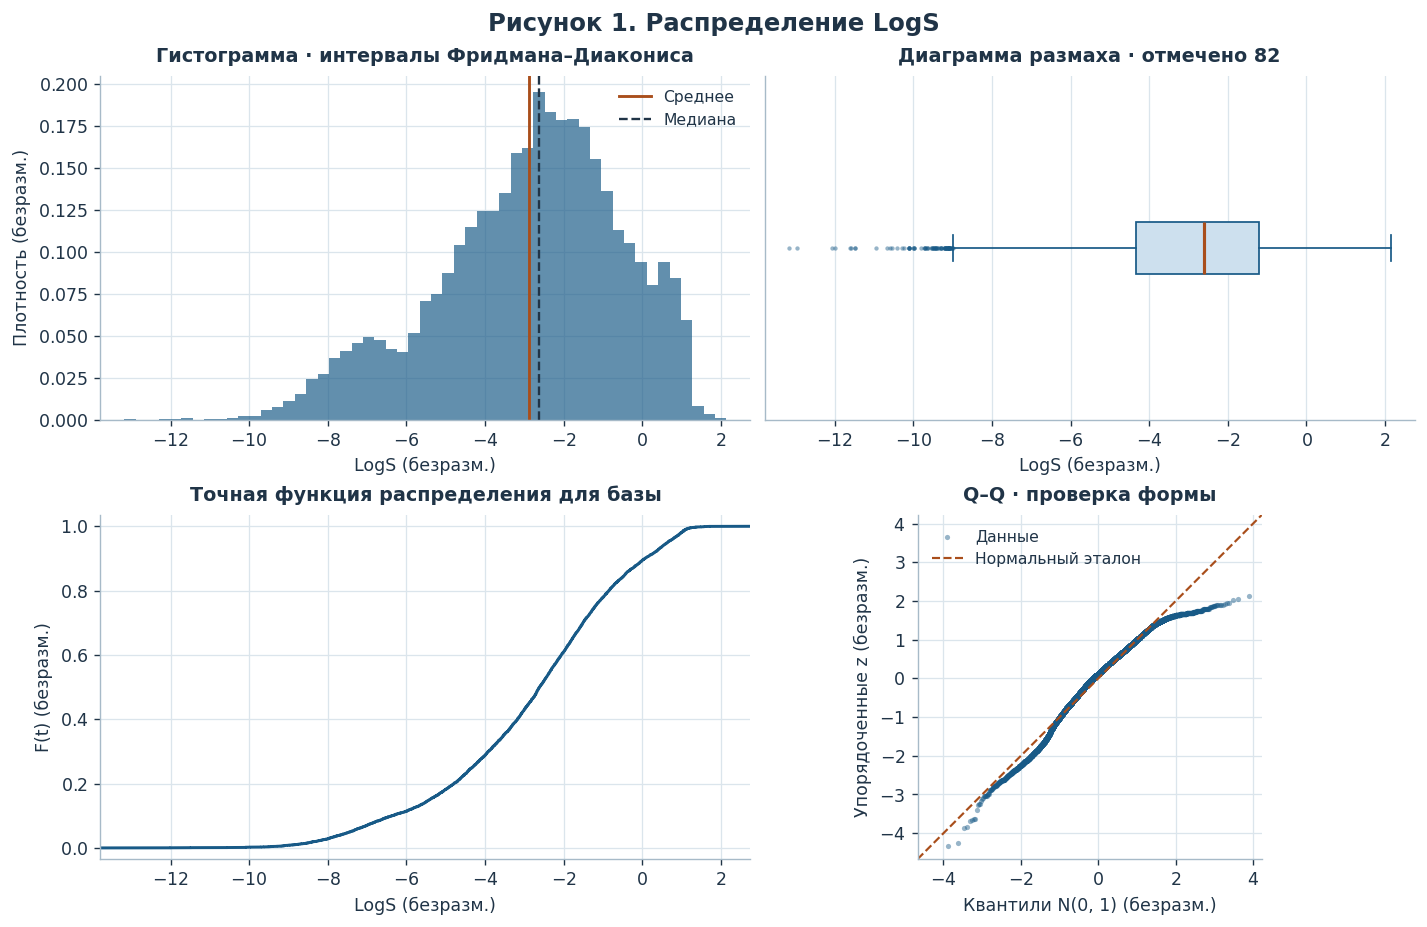

In [3]:
#@title Описательные статистики и графики: LogS { display-mode: "form" }
eda("LogS", 1)

<a id="logs-est" name="logs-est"></a>

### 1.1.3 Независимость и оценки

До отбора значение LogS случайно; связь с обоими признаками той же строки проверяется в [разделе 1.4](#lab01-hypotheses). Ниже сопоставлены оценки для двух схем отбора и весь AqSolDB. Сдвиг - разность среднего выборки и среднего базы, со знаком.

,Объём,Уникальных соединений,"Среднее, безразм.","Дисперсия, безразм.","Сдвиг среднего, безразм.","Абс. ошибка среднего, безразм.","Станд. ошибка, безразм."
Отбор,,,,,,,
С возвращением,500,486,-2.9072,5.2712,-0.0173,0.0173,0.1059
Без возвращения,500,500,-2.8345,5.3884,0.0554,0.0554,0.1032
Вся база,9982,9982,-2.8899,5.6076,0.0000,0.0000,NaN


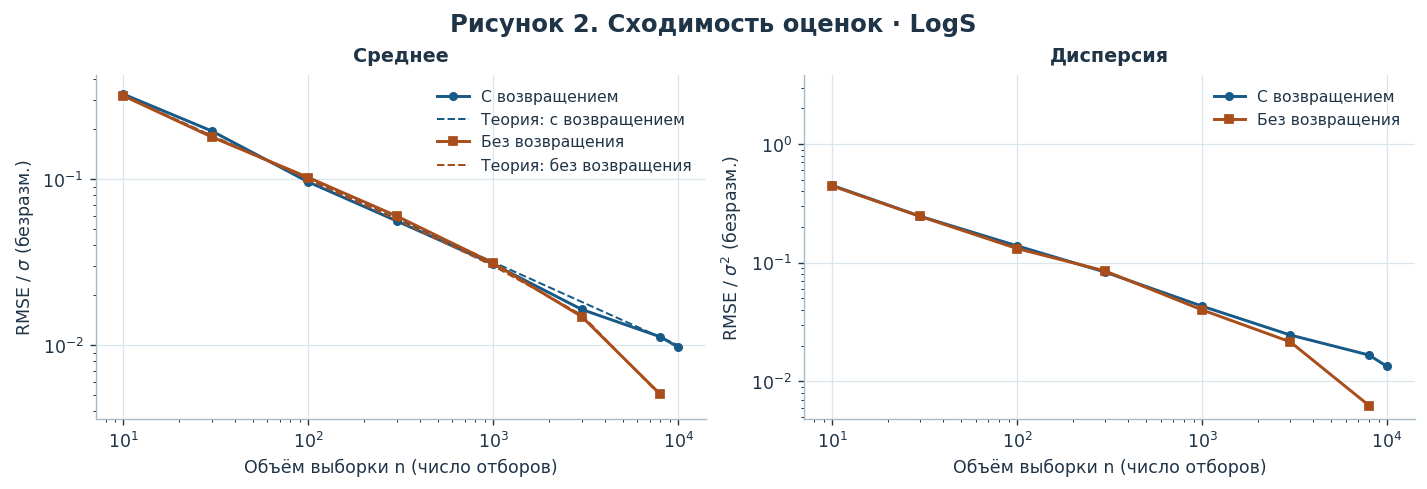

In [4]:
#@title Выборочные оценки и сходимость: LogS { display-mode: "form" }
comparison("LogS", 2)

<a id="lab01-molwt" name="lab01-molwt"></a>

## 1.2 Случайная величина №2: MolWt

[К оглавлению](#lab01-toc)

<a id="molwt-desc" name="molwt-desc"></a>

### 1.2.1 Описание

`MolWt` - средняя молекулярная масса из [документации RDKit](https://www.rdkit.org/docs/source/rdkit.Chem.Descriptors.html), представленная как молярная масса в г/моль. Для фиксированного соединения её можно вычислить по составу с учётом изотопов; поэтому не считаем алгоритм RDKit источником случайности. До отбора состав соединения неизвестен, и разные строки имеют разные массы.

$$
X_2=M_I,\qquad M_i>0,\qquad [M_i]=\mathrm{g}\,\mathrm{mol}^{-1}.
$$

<a id="molwt-eda" name="molwt-eda"></a>

### 1.2.2 EDA и дистрибуция

Среднее заметно больше медианы: редкие большие массы растягивают правый хвост. Показываем весь диапазон, не срезая тяжёлые соединения. Отдельно исследуем логарифм массы, чтобы уменьшить асимметрию и сравнивать относительные изменения, а не разности в г/моль:

$$
T=\log_{10}\!\left(\frac{X_2}{1\,\mathrm{g}\,\mathrm{mol}^{-1}}\right).
$$

Если бы $T$ имела нормальный закон, масса была бы логнормальной. На логарифмической шкале асимметрия уменьшается, но хвосты на Q-Q-графике всё ещё отклоняются от диагонали; логнормальность остаётся приближением, а не установленным законом.

,Значение,Единица
Статистика,,
Число соединений,9982.0000,шт.
Среднее,266.6659,г/моль
Дисперсия,33918.5144,(г/моль)²
Стандартное отклонение,184.1698,г/моль
Минимум,9.0120,г/моль
Первый квартиль,162.2760,г/моль
Медиана,228.6820,г/моль
Третий квартиль,320.4360,г/моль
Максимум,5299.4560,г/моль


,Среднее,Станд. отклонение,Мин.,Макс.
z-стандартизация,-0.0000,1.0000,-1.399,27.3269
Min–max,0.0487,0.0348,0.000,1.0000


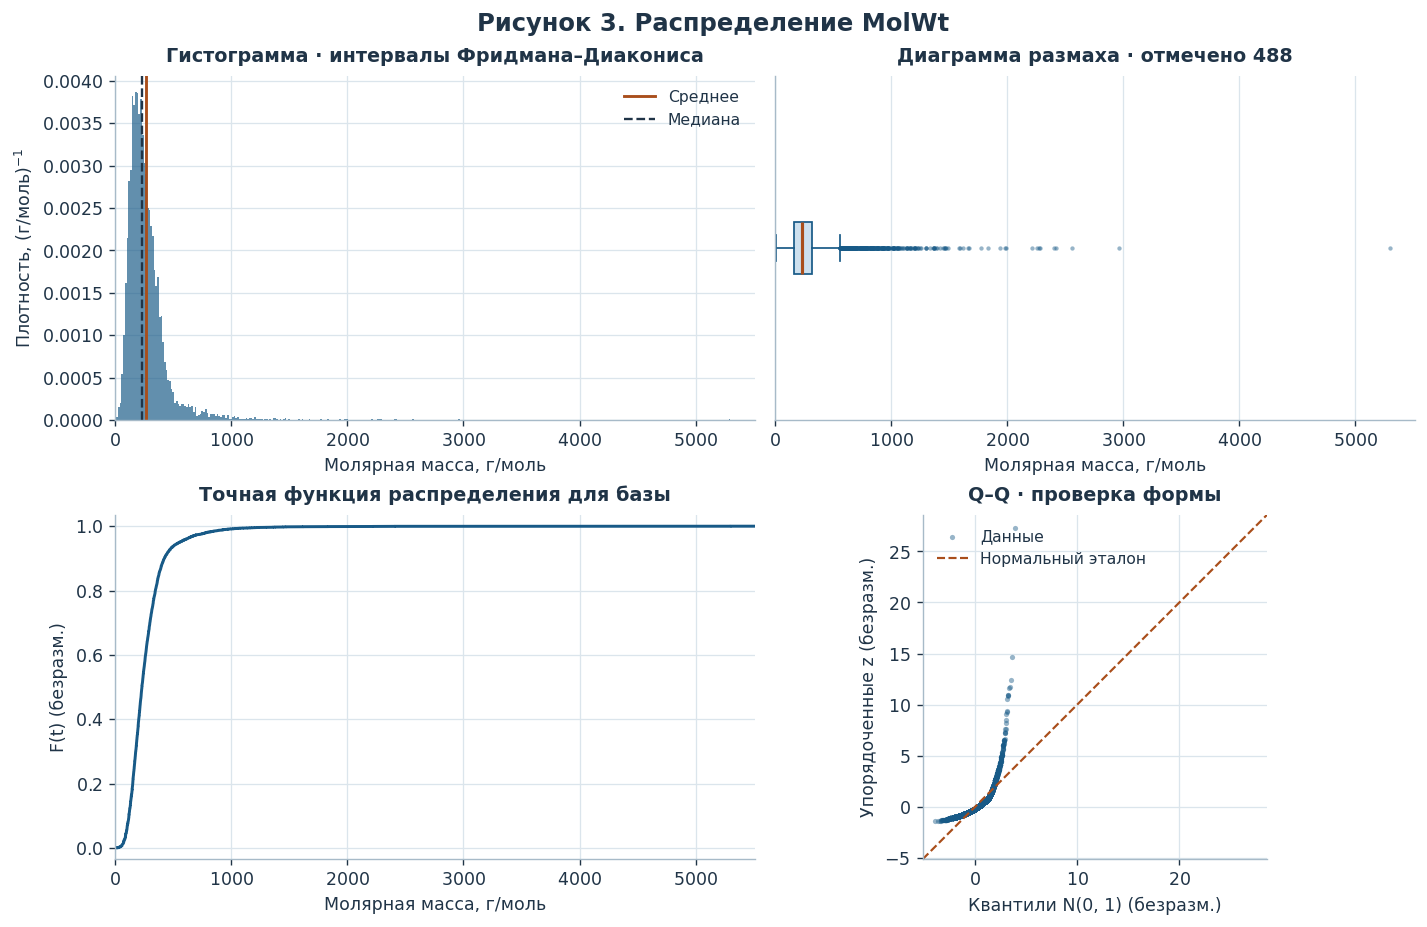

In [5]:
#@title Описательные статистики и графики: MolWt { display-mode: "form" }
eda("MolWt", 3)

Асимметрия до преобразования: 5.494; после: 0.045.


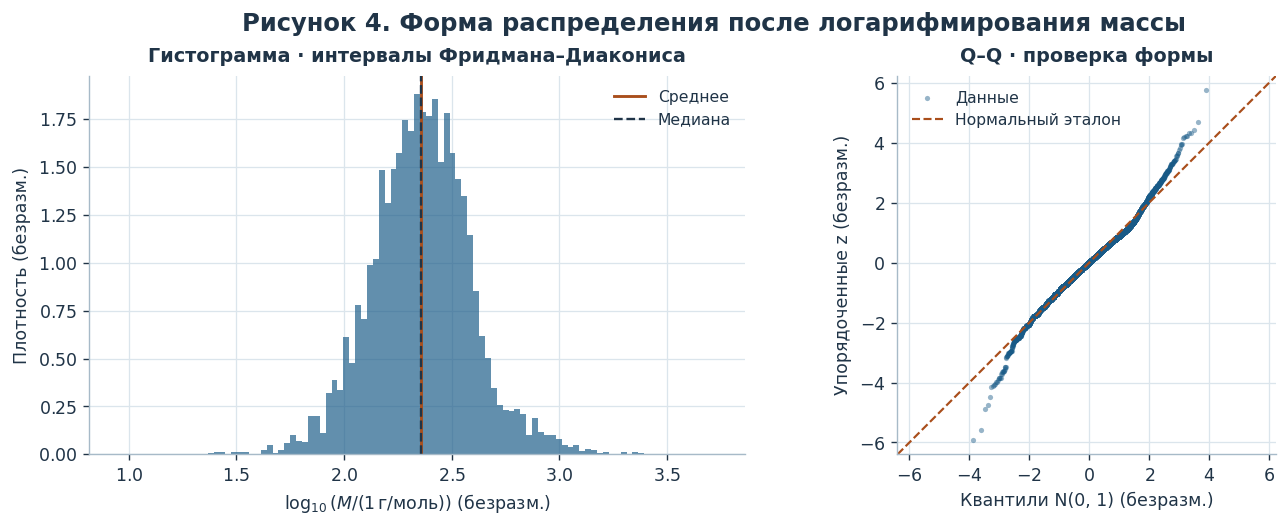

In [6]:
#@title Логарифм массы: плотность и Q–Q { display-mode: "form" }
t = np.log10(data["MolWt"].to_numpy())
fig, ax = plt.subplots(1, 2, figsize=(11.3, 4.1), layout="constrained")
fig.suptitle("Рисунок 4. Форма распределения после логарифмирования массы",
             fontsize=14, fontweight="bold")
draw_hist(ax[0], t, r"$\log_{10}(M/(1\,\mathrm{г/моль}))$ (безразм.)", "безразм.")
draw_qq(ax[1], (t - t.mean()) / t.std())
show(fig)
print(f"Асимметрия до преобразования: {stats.skew(data['MolWt']):.3f}; "
      f"после: {stats.skew(t):.3f}.")

<a id="molwt-est" name="molwt-est"></a>

### 1.2.3 Независимость и оценки

Ниже сравниваются оценки на исходной шкале массы. Из-за правого хвоста несколько тяжёлых соединений могут сильно сдвинуть результат, особенно оценку дисперсии. Связь с LogS и MolLogP проверяется в [разделе 1.4](#lab01-hypotheses).

,Объём,Уникальных соединений,"Среднее, г/моль","Дисперсия, (г/моль)²","Сдвиг среднего, г/моль","Абс. ошибка среднего, г/моль","Станд. ошибка, г/моль"
Отбор,,,,,,,
С возвращением,500,486,273.8043,34904.6713,7.1384,7.1384,8.2363
Без возвращения,500,500,259.9217,33878.9287,-6.7442,6.7442,8.0278
Вся база,9982,9982,266.6659,33918.5144,0.0000,0.0000,NaN


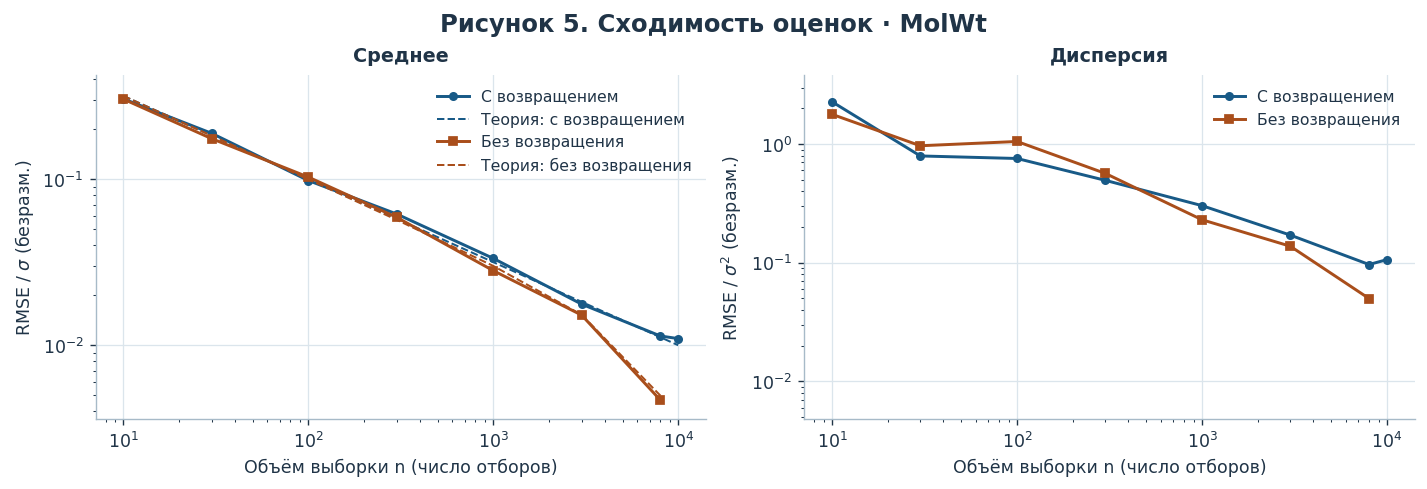

In [7]:
#@title Выборочные оценки и сходимость: MolWt { display-mode: "form" }
comparison("MolWt", 5)

<a id="lab01-logp" name="lab01-logp"></a>

## 1.3 Случайная величина №3: MolLogP

[К оглавлению](#lab01-toc)

<a id="logp-desc" name="logp-desc"></a>

### 1.3.1 Описание

`MolLogP` - расчётный дескриптор липофильности, а не прямое измерение. Он оценивает десятичный логарифм безразмерного коэффициента распределения между октанолом и водой. В [RDKit, метод Wildman-Crippen](https://www.rdkit.org/docs/cppapi/namespaceRDKit_1_1Descriptors.html) оценка строится по вкладам атомов заданных типов.

$$
X_3=\widehat{\log_{10}P}(I),\qquad
P=\frac{c_{\mathrm{octanol}}}{c_{\mathrm{water}}}.
$$

При фиксированной молекулярной структуре дескриптор детерминирован. Как и для массы, случайна строка, по которой берём результат вычисления. Дескриптор оценивает экспериментальный коэффициент по структуре молекулы.

<a id="logp-eda" name="logp-eda"></a>

### 1.3.2 EDA и дистрибуция

Среднее и медиана близки, но это не признак нормального закона. Положительный эксцесс и выраженные отклонения на концах Q-Q-графика показывают, что в базе есть редкие крайние значения по обе стороны основной массы наблюдений. Они оставлены в анализе.
Дополнительно сравниваем гистограмму и оценку плотности KDE с нормальной кривой, параметры которой подогнаны по данным. Кривая служит ориентиром для сравнения формы.


,Значение,Единица
Статистика,,
Число соединений,9982.0000,шт.
Среднее,1.9792,безразм.
Дисперсия,12.3732,безразм.
Стандартное отклонение,3.5176,безразм.
Минимум,-40.8732,безразм.
Первый квартиль,0.6197,безразм.
Медиана,1.9492,безразм.
Третий квартиль,3.4190,безразм.
Максимум,68.5411,безразм.


,Среднее,Станд. отклонение,Мин.,Макс.
z-стандартизация,-0.0000,1.0000,-12.1824,18.9228
Min–max,0.3917,0.0321,0.0000,1.0000


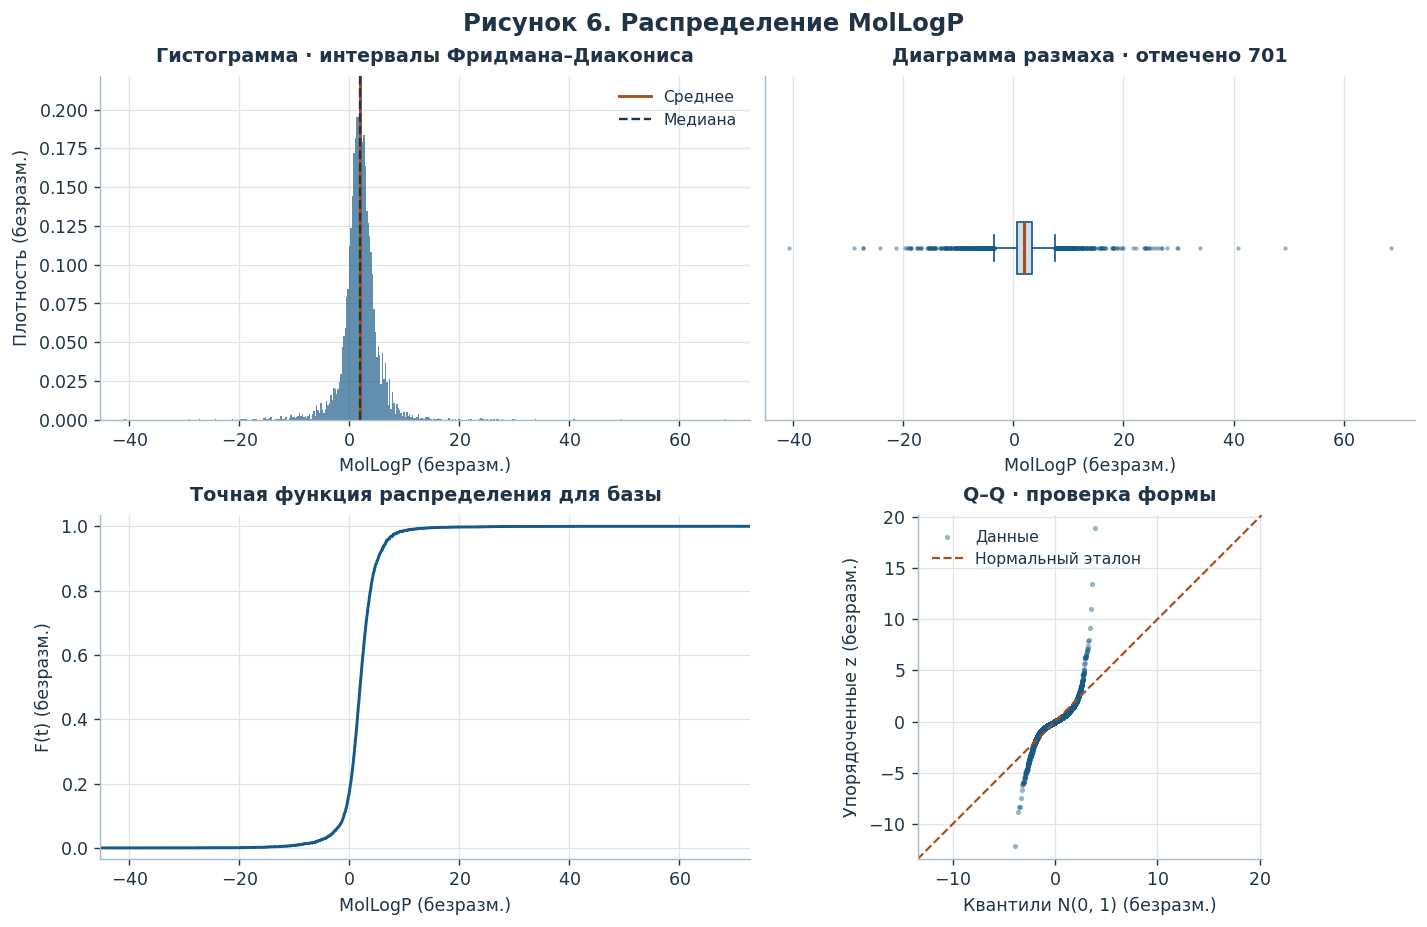

In [8]:
#@title Описательные статистики и графики: MolLogP { display-mode: "form" }
eda("MolLogP", 6)

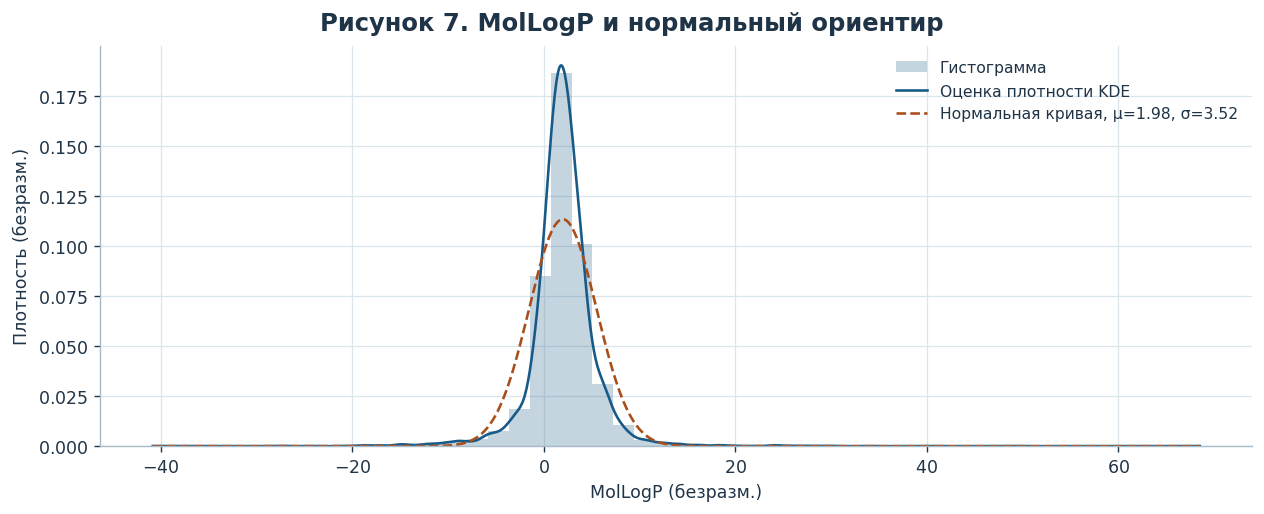

In [9]:
#@title MolLogP: сравнение плотностей { display-mode: "form" }
logp = data["MolLogP"].to_numpy()
fit_mu, fit_sigma = stats.norm.fit(logp)
grid = np.linspace(logp.min(), logp.max(), 1200)
fig, axis = plt.subplots(figsize=(10, 4), layout="constrained")
fig.suptitle("Рисунок 7. MolLogP и нормальный ориентир", fontsize=14, fontweight="bold")
axis.hist(logp, bins=50, density=True, alpha=.25, color=BLUE, label="Гистограмма")
axis.plot(grid, stats.gaussian_kde(logp)(grid), color=BLUE, label="Оценка плотности KDE")
axis.plot(grid, stats.norm.pdf(grid, fit_mu, fit_sigma), "--", color=ORANGE,
          label=f"Нормальная кривая, μ={fit_mu:.2f}, σ={fit_sigma:.2f}")
axis.set(xlabel=LABEL["MolLogP"], ylabel="Плотность (безразм.)", ylim=(0, None))
axis.legend()
show(fig)


<a id="logp-est" name="logp-est"></a>

### 1.3.3 Независимость и оценки

Оценки рассчитаны теми же способами и по тем же строкам, что для первых двух признаков. Почти одинаковые среднее и медиана всей базы не устраняют влияния крайних значений на дисперсию. Связи с двумя другими признаками разбираются в [разделе 1.4](#lab01-hypotheses).
Таблица единичных выборок показывает, что абсолютная ошибка при одном отборе может колебаться с ростом объёма. На графике сходимости показана уже среднеквадратичная ошибка по 200 повторам.


,Объём,Уникальных соединений,"Среднее, безразм.","Дисперсия, безразм.","Сдвиг среднего, безразм.","Абс. ошибка среднего, безразм.","Станд. ошибка, безразм."
Отбор,,,,,,,
С возвращением,500,486,1.8926,12.4999,-0.0866,0.0866,0.1573
Без возвращения,500,500,1.8808,13.6031,-0.0983,0.0983,0.1533
Вся база,9982,9982,1.9792,12.3732,0.0000,0.0000,NaN


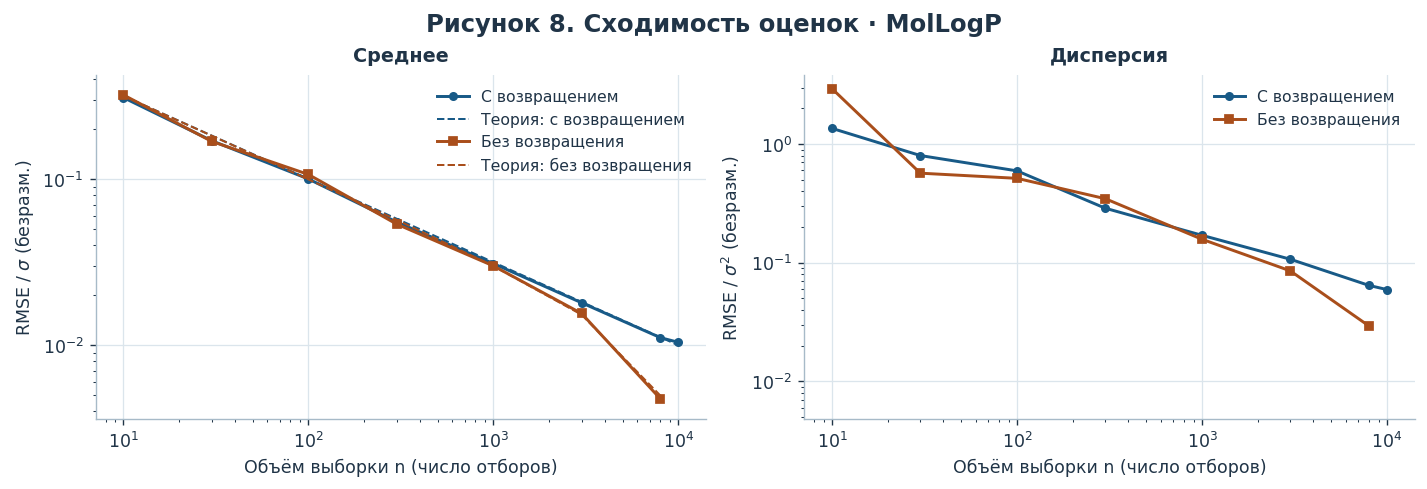

In [10]:
#@title Выборочные оценки и сходимость: MolLogP { display-mode: "form" }
comparison("MolLogP", 8)

In [11]:
#@title MolLogP: единичные выборки для разных объёмов { display-mode: "form" }
rng_logp = np.random.RandomState(SEED)
logp_examples = []
for sample_size in (10, 50, 100, 500, 1000, 5000):
    for replace_rows in (False, True):
        estimate = data["MolLogP"].sample(sample_size, replace=replace_rows,
                                         random_state=rng_logp).mean()
        logp_examples.append({
            "Объём": sample_size, "Отбор": methods[replace_rows], "Среднее": estimate,
            "Абс. ошибка среднего": abs(estimate - mu["MolLogP"]),
        })
logp_example_table = pd.DataFrame(logp_examples)
display(logp_example_table.pivot(index="Объём", columns="Отбор").round(4))


Среднее                Абс. ошибка среднего               
Отбор Без возвращения С возвращением      Без возвращения С возвращением
Объём                                                                   
10             2.0959         2.5485               0.1167         0.5693
50             1.6730         1.5483               0.3061         0.4309
100            2.1178         2.0958               0.1387         0.1166
500            1.9077         1.7085               0.0715         0.2707
1000           1.9692         1.7929               0.0100         0.1862
5000           1.9415         1.9703               0.0376         0.0089

<a id="lab01-hypotheses" name="lab01-hypotheses"></a>

## 1.4 Зависимость и проверка гипотез

[К оглавлению](#lab01-toc)

<a id="lab01-finite" name="lab01-finite"></a>

### 1.4.1 Проверка независимости в конечной совокупности

Для каждой пары обозначим через $A$ и $B$ события «соответствующий признак не выше своей медианы по базе». Считаем числа строк $n_A$, $n_B$ и $n_{AB}$. Для независимых признаков равенство вероятностей должно выполняться для любых порогов, поэтому достаточно одного контрпримера. Сравниваем целые числа, чтобы не спутать расхождение с погрешностью округления.

$$
\Pr(A\cap B)=\Pr(A)\Pr(B)
\quad\Longleftrightarrow\quad
Nn_{AB}=n_A n_B.
$$

Диаграммы ниже показывают все наблюдения. Цвет кодирует число строк в шестиграннике по общей логарифмической шкале; оси самих признаков линейные. Коэффициенты Пирсона и Спирмена описывают линейную и монотонную связь соответственно. Тепловые карты показывают эти же коэффициенты на общей шкале от −1 до 1. Корреляция описывает связь в базе.

,n(A),n(B),n(A ∩ B),P(A ∩ B),P(A)·P(B),Равенство выполнено,Пирсон,Спирмен
Пара,,,,,,,,
LogS / MolWt,4991,4993,1465,0.1468,0.2501,False,-0.3680,-0.5386
LogS / MolLogP,4991,4991,1018,0.1020,0.2500,False,-0.6086,-0.7398
MolWt / MolLogP,4993,4991,3296,0.3302,0.2501,False,0.2745,0.4216


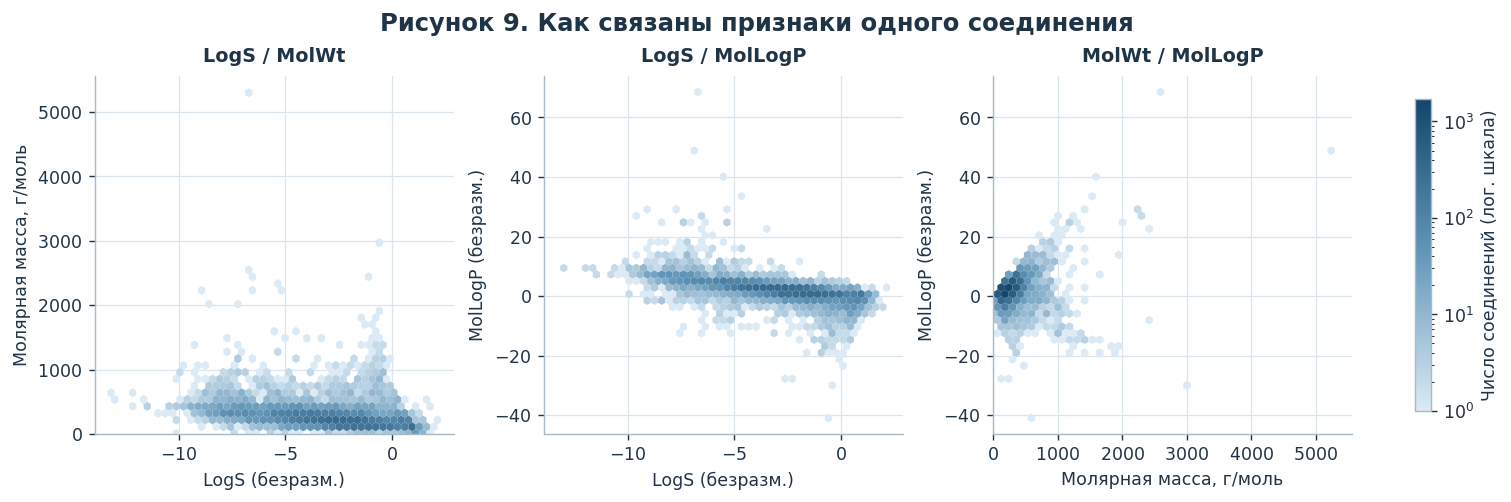

In [12]:
#@title Точный контрпример, корреляции и диаграммы связей { display-mode: "form" }
pairs = list(combinations(FEATURES, 2))
events = data.le(data.median())
dep_rows = []
for left, right in pairs:
    a, b = int(events[left].sum()), int(events[right].sum())
    ab = int((events[left] & events[right]).sum())
    dep_rows.append({
        "Пара": f"{left} / {right}", "n(A)": a, "n(B)": b, "n(A ∩ B)": ab,
        "P(A ∩ B)": ab / N, "P(A)·P(B)": a * b / N**2,
        "Равенство выполнено": N * ab == a * b,
        "Пирсон": stats.pearsonr(data[left], data[right]).statistic,
        "Спирмен": stats.spearmanr(data[left], data[right]).statistic,
    })
dependence = pd.DataFrame(dep_rows).set_index("Пара")
display(dependence.round(4))

cmap = LinearSegmentedColormap.from_list("aqsol-blue", ["#dbeaf4", "#6597b9", "#13466b"])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.9), layout="constrained")
fig.suptitle("Рисунок 9. Как связаны признаки одного соединения", fontsize=14, fontweight="bold")
hexbins = []
for axis, (left, right) in zip(ax, pairs):
    h = axis.hexbin(data[left], data[right], gridsize=45, mincnt=1, cmap=cmap, linewidths=0)
    assert h.get_array().sum() == N
    hexbins.append(h)
    axis.set(title=f"{left} / {right}", xlabel=LABEL[left], ylabel=LABEL[right])
    if left == "MolWt":
        axis.set_xlim(left=0)
    if right == "MolWt":
        axis.set_ylim(bottom=0)
shared = LogNorm(vmin=1, vmax=max(h.get_array().max() for h in hexbins))
for h in hexbins:
    h.set_norm(shared)
fig.colorbar(hexbins[0], ax=ax, label="Число соединений (лог. шкала)", shrink=.87)
show(fig)

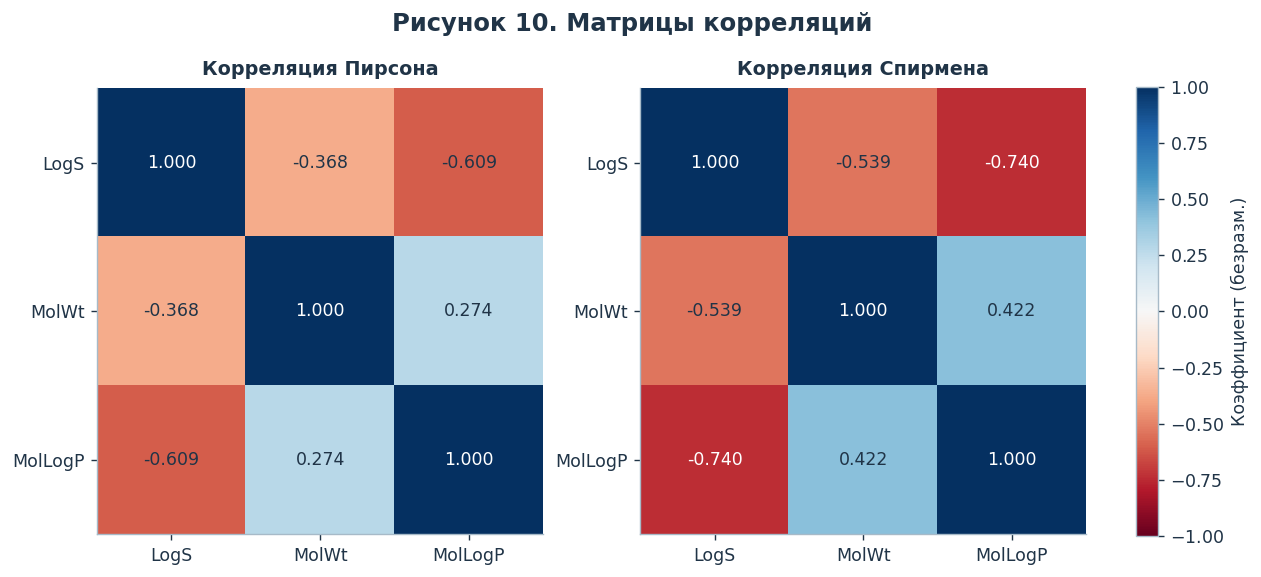

In [13]:
#@title Матрицы корреляций Пирсона и Спирмена { display-mode: "form" }
corr_matrices = {name: data.corr(method=method)
                 for name, method in (("Пирсона", "pearson"), ("Спирмена", "spearman"))}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), layout="constrained")
fig.suptitle("Рисунок 10. Матрицы корреляций", fontsize=14, fontweight="bold")
for axis, (name, matrix) in zip(axes, corr_matrices.items()):
    color = axis.imshow(matrix, cmap="RdBu", vmin=-1, vmax=1)
    axis.set(title=f"Корреляция {name}", xticks=range(3), yticks=range(3),
             xticklabels=FEATURES, yticklabels=FEATURES)
    axis.grid(False)
    for row, col in np.ndindex(matrix.shape):
        r = matrix.iat[row, col]
        axis.text(col, row, f"{r:.3f}", ha="center", va="center",
                  color="white" if abs(r) > .62 else INK)
fig.colorbar(color, ax=axes, shrink=.85, label="Коэффициент (безразм.)")
show(fig)


<a id="lab01-test" name="lab01-test"></a>

### 1.4.2 Перестановочная проверка на выборке

В исходнике для LogS и MolLogP использовали тест Пирсона на всей базе. Здесь коэффициент Пирсона для всей базы приводим как описательную статистику. Значимость проверяем отдельно для всех трёх пар в случайной выборке.

Проверяем, видна ли зависимость по выборке из $n=500$ независимых отборов с возвращением. Для каждой пары $H_0$: признаки независимы в выбранной совокупности, поэтому вторую координату можно переставлять между строками без изменения совместного закона. $H_1$: независимость нарушена. Статистика $\lvert r\rvert$ чувствительна прежде всего к связи, проявляющейся в линейной корреляции; неотклонение не доказывало бы независимость. Модули нужны для двусторонней проверки.

Для каждой пары делаем $R=9999$ случайных перестановок и сравниваем их корреляции $r_b^{*}$ с наблюдаемой $r_{\mathrm{obs}}$. Применяем поправку Бонферрони для трёх пар и сравниваем скорректированное значение с уровнем $\alpha=0.05$.

$$
p=\frac{1+\sum_{b=1}^{R}\mathbf{1}\{\lvert r_b^{*}\rvert\geq\lvert r_{\mathrm{obs}}\rvert\}}{R+1},
\qquad p_{\mathrm{adj}}=\min(1,3p).
$$

In [14]:
#@title Перестановочный тест: три пары, поправка Бонферрони { display-mode: "form" }
R, alpha = 9999, .05
trial = data.iloc[rng_test.choice(N, size=500, replace=True)]
test_rows = []
for left, right in pairs:
    x, y = trial[left].to_numpy(), trial[right].to_numpy()
    x, y = x - x.mean(), y - y.mean()
    divisor = np.linalg.norm(x) * np.linalg.norm(y)
    r_obs = float(x @ y / divisor)
    exceed = sum(abs(x @ rng_perm.permutation(y) / divisor) >= abs(r_obs) - 1e-14
                 for _ in range(R))
    p = (1 + exceed) / (R + 1)
    adjusted = min(1, len(pairs) * p)
    test_rows.append({"Пара": f"{left} / {right}", "r в выборке": r_obs,
                      "Не менее экстремальных": exceed, "p": p, "p с поправкой": adjusted,
                      "Решение при α = 0,05": "Отклоняем H₀" if adjusted <= alpha else "Не отклоняем H₀"})
tests = pd.DataFrame(test_rows).set_index("Пара")
assert tests["p"].between(1 / (R + 1), 1).all()
display(tests.round(5))

,r в выборке,Не менее экстремальных,p,p с поправкой,"Решение при α = 0,05"
Пара,,,,,
LogS / MolWt,-0.39207,0,0.0001,0.0003,Отклоняем H₀
LogS / MolLogP,-0.68894,0,0.0001,0.0003,Отклоняем H₀
MolWt / MolLogP,0.35285,0,0.0001,0.0003,Отклоняем H₀


<a id="lab01-resume" name="lab01-resume"></a>

## 1.5 Выводы по спринту 1

LogS имеет левый хвост, MolWt — выраженный правый хвост, а у MolLogP встречаются редкие крайние значения. Поэтому форму распределений оцениваем вместе со средним, разбросом, асимметрией и эксцессом.

С ростом объёма выборки среднеквадратичная ошибка оценок в целом снижается. Абсолютная ошибка отдельной случайной выборки может колебаться. При отборе всех строк без возвращения среднее и дисперсия совпадают с показателями базы.

В AqSolDB все три пары признаков зависимы по проверке вероятностей. Самая сильная по модулю корреляция наблюдается между LogS и MolLogP: более липофильные соединения в этой базе обычно имеют меньшую растворимость.

[К оглавлению](#lab01-toc)


In [15]:
#@title Сводная таблица результата { display-mode: "form" }
out = pd.DataFrame({
    "Единица исходного признака": pd.Series(UNIT), "Среднее базы": mu,
    "Медиана базы": data.median(), "Дисперсия базы": var,
    "Отмечено по Тьюки": {c: eda_metrics[c]["flagged"] for c in FEATURES}, "Асимметрия": {c: eda_metrics[c]["skew"] for c in FEATURES},
    "Эксцесс": {c: eda_metrics[c]["excess"] for c in FEATURES},
})
wr = mc[mc["Отбор"].eq(methods[True])]
for n in (min(sizes), N):
    for key, title in (("mean_rmse", "RMSE среднего / σ"), ("var_rmse", "RMSE дисперсии / σ²")):
        out[f"{title}, n={n}"] = wr[wr["n"].eq(n)].set_index("Признак")[key]
display(out.round(4))
print("Ошибка переписи без возвращения: ноль для среднего и дисперсии всех трёх признаков.")
print("После поправки Бонферрони отвергнуто гипотез независимости:",
      int((tests["p с поправкой"] <= alpha).sum()), "из", len(pairs))

Ошибка переписи без возвращения: ноль для среднего и дисперсии всех трёх признаков.
После поправки Бонферрони отвергнуто гипотез независимости: 3 из 3


,Единица исходного признака,Среднее базы,Медиана базы,Дисперсия базы,Отмечено по Тьюки,Асимметрия,Эксцесс,"RMSE среднего / σ, n=10","RMSE дисперсии / σ², n=10","RMSE среднего / σ, n=9982","RMSE дисперсии / σ², n=9982"
LogS,безразм.,-2.8899,-2.6182,5.6076,82,-0.5516,-0.0600,0.3241,0.4490,0.0097,0.0134
MolWt,г/моль,266.6659,228.6820,33918.5144,488,5.4938,80.9231,0.3036,2.2749,0.0110,0.1061
MolLogP,безразм.,1.9792,1.9492,12.3732,701,0.7182,29.5092,0.3089,1.3572,0.0104,0.0593


<a id="lab01-cat_mark_table" name="lab01-cat_mark_table"></a>

### 1.6 Критерии оценивания по спринту 1

| cat_id | notebook_link | coeff | comment |
|:---|:---|:---:|:---|
| 1 | [Выбор датасета](#lab01-data) | – | Выбор датасета для дальнейшей работы. |
| 2 | [Химическая интерпретация LogS](#lab01-logs) | – | Понимание водной растворимости и физического смысла логарифмической шкалы. |
| 3 | [Химическая интерпретация MolWt](#lab01-molwt) | – | Понимание молярной массы и её связи с молекулярным составом. |
| 4 | [Химическая интерпретация MolLogP](#lab01-logp) | – | Понимание липофильности и коэффициента распределения октанол–вода. |
| 5 | [Обоснование выбора случайных величин](#lab01-methods) | – | Объяснение стохастической природы признаков через случайный выбор химического соединения. |
| 6 | [Корректность обработки химических данных](#lab01-data) | – | Проверка дубликатов, InChIKey, пропусков и допустимых значений химических дескрипторов. |
| 7 | [Интерпретация химических закономерностей](#lab01-hypotheses) | – | Объяснение обнаруженных связей между растворимостью, молярной массой и липофильностью. |
| 8 | [Выводы по спринту 1](#lab01-resume) | – | Вывод по проделанной в спринте 1 работе. |

[К оглавлению](#lab01-toc)

<a id="lab02-sprint" name="lab02-sprint"></a>

# Спринт 2

[К оглавлению](#lab01-toc) · [К итогам первого спринта](#lab01-resume)


<a id="lab02-generator" name="lab02-generator"></a>

## 2.1 Генераторы LogS


<a id="lab02-desc" name="lab02-desc"></a>

### 2.1.1 Описание

Из исходного второго спринта переносим два способа генерации LogS. Первый выбирает наблюдавшиеся значения по обратной эмпирической функции распределения. Второй строит квантильную функцию с линейной интерполяцией. Оба используют форму исходных данных, которая отклоняется от нормальной.

Для сравнения один раз перемешиваем очищенные строки AqSolDB и делим их на обучающую часть (80% с округлением вниз) и отложенную часть (остаток). Оба генератора обучаются на одних строках и проверяются на одной и той же отложенной части. Объём каждой синтетической выборки равен объёму отложенной части. Разные соединения в обеих частях могут иметь одинаковое значение LogS.


<a id="lab02-math" name="lab02-math"></a>

### 2.1.2 Метод и обоснование

Пусть $m$ обозначает число обучающих строк, а $x_{(1)}\le \cdots \le x_{(m)}$ их значения LogS после сортировки. Эмпирическая функция распределения ступенчатая:

$$
\widehat F_m(t)=\frac{1}{m}\sum_{i=1}^{m}\mathbf{1}\{x_{(i)}\le t\}.
$$

Для каждого нового числа берём $U\sim\operatorname{Unif}[0,1)$, вычисляем номер $J$ и возвращаем соответствующее значение:

$$
J=\lfloor mU\rfloor+1,\qquad Y=x_{(J)}.
$$

Зачем здесь умножение на $m$? Оно разбивает единичный интервал на $m$ интервалов равной вероятности. Например, если в обучении четыре строки, то $U=0.62$ попадает в третий интервал, поэтому возвращается третье значение после сортировки. В общем случае

$$
\Pr(J=j)=\Pr\!\left(\frac{j-1}{m}\le U<\frac{j}{m}\right)=\frac1m,
\qquad j=1,\ldots,m.
$$

Суммируя эти вероятности по всем позициям, где $x_{(j)}\le t$, получаем $\Pr(Y\le t\mid x_{(1)},\ldots,x_{(m)})=\widehat F_m(t)$. У ступенчатой функции нет обычной обратной, поэтому используем выбор по квантильным интервалам ([принцип инверсии в книге Л. Девруа](https://link.springer.com/chapter/10.1007/978-1-4613-8643-8_2)). Реализация использует интервалы, замкнутые слева; это может менять выбор на границах относительно определения обобщённого квантиля через $\inf\{t:\widehat F_m(t)\ge u\}$, но границы имеют нулевую вероятность в непрерывной математической модели. В Python индекс начинается с нуля, поэтому добавлять единицу не нужно.

Для первого метода это **равномерный выбор строки**, а не равномерный выбор среди различных значений LogS. Если одно и то же число встречается в трёх строках, оно получает три интервала. Равенство доказано для обучающего распределения; совпадение с отложенной частью надо измерять отдельно. Дискретный метод возвращает только значения из обучающего набора.


**Квантильный генератор с интерполяцией.** Для тех же упорядоченных значений задаём узлы (p_j=(j-1)/(m-1)), когда (mge 2). При (Uin[p_j,p_{j+1})) возвращаем

$$
Y=x_{(j)}+rac{U-p_j}{p_{j+1}-p_j}igl(x_{(j+1)}-x_{(j)}igr).
$$

Если соседние значения совпадают, весь интервал даёт одно значение. Если они различаются, генератор может вернуть промежуточный LogS. Результаты остаются между минимумом и максимумом обучения. При (m=1) всегда возвращаем единственное значение. Интерполяция задаёт сглаженную квантильную функцию и меняет закон по сравнению со ступенчатым эмпирическим распределением.


<a id="lab02-code" name="lab02-code"></a>

### 2.1.3 Реализация

Оба алгоритма включены в ноутбук. Дискретный метод выбирает индекс через округление вниз, интерполяционный использует `np.interp` на равномерной сетке вероятностей. Используем одинаковые равномерные числа для обоих методов, чтобы сравнить преобразования на одних входах. Для повторного запуска используйте «Restart Kernel and Run All Cells»: первый спринт загружает и проверяет исходный CSV. Если сеть недоступна, положите рядом с ноутбуком [зафиксированный CSV](https://raw.githubusercontent.com/mcsorkun/AqSolDB/98cdd10a372058743e4f3fb950a1c9974ec9603a/results/data_curated.csv) с именем `data_curated.csv`.

Технические ячейки свёрнуты, но их можно раскрыть: в JupyterLab через переключатель слева от ячейки, в Colab через кнопку показа кода. Таблицы и рисунки остаются видимыми.


In [16]:
#@title Генератор LogS и отложенное разбиение { display-mode: "form" }
def s2_generate(values, n, rng):
    "Выбор по обратной эмпирической функции распределения."
    sorted_values = np.sort(values)
    u = rng.random(n)
    indices = np.floor(u * len(sorted_values)).astype(int)
    return sorted_values[indices]


def generate_logs_quantile(values, n, rng):
    """Линейная интерполяция между соседними порядковыми статистиками."""
    if n <= 0:
        raise ValueError("Размер генерации должен быть положительным.")
    values = np.asarray(values, dtype=float)
    sorted_values = np.sort(values[np.isfinite(values)])
    if sorted_values.size == 0:
        raise ValueError("В обучающем наборе нет конечных значений.")
    grid = np.linspace(0, 1, sorted_values.size)
    return np.interp(rng.random(n), grid, sorted_values)


def s2_metrics(values):
    q05, q25, q50, q75, q95 = np.quantile(values, [.05, .25, .5, .75, .95])
    return {
        "Среднее": np.mean(values),
        "Стандартное отклонение": np.std(values, ddof=1),
        "Медиана": q50,
        "Первый квартиль": q25,
        "Третий квартиль": q75,
        "Межквартильный размах": q75 - q25,
        "Квантиль 5%": q05,
        "Квантиль 95%": q95,
        "Минимум": np.min(values),
        "Максимум": np.max(values),
        "Асимметрия": stats.skew(values, bias=True),
        "Эксцесс": stats.kurtosis(values, fisher=True, bias=True),
    }


s2_values = data["LogS"].to_numpy(dtype=float)
s2_rng = np.random.default_rng(SEED)
s2_perm = s2_rng.permutation(len(s2_values))
s2_cut = int(.8 * len(s2_values))
s2_ix_train, s2_ix_test = s2_perm[:s2_cut], s2_perm[s2_cut:]
s2_train, s2_test = s2_values[s2_ix_train], s2_values[s2_ix_test]
from copy import deepcopy

s2_interpolation_rng = deepcopy(s2_rng)
s2_generated = s2_generate(s2_train, s2_test.size, s2_rng)
s2_interpolated = generate_logs_quantile(s2_train, s2_test.size, s2_interpolation_rng)


<a id="lab02-tests" name="lab02-tests"></a>

### 2.1.4 Автотесты

Проверяем размер результата и его принадлежность обучающему набору, воспроизводимость с одинаковым начальным состоянием, индексацию на границах и сохранение кратности повторов. Проверка среднего на большой генерации использует фиксированное начальное состояние и известную стандартную ошибку для выборки с возвращением; она не заменяет проверку на отложенных данных. Отдельные тесты проверяют разбиение, размер и диапазон интерполяционной выборки, её воспроизводимость и расчёт промежуточного квантиля.


In [17]:
#@title Автотесты генератора { display-mode: "form" }
import io as s2_io
import unittest as s2_unittest


class Sprint2GeneratorTests(s2_unittest.TestCase):
    def setUp(self):
        self.values = np.random.default_rng(1).normal(-3, 1.5, 1000)

    def test_size_and_support(self):
        sample = s2_generate(self.values, 500, np.random.default_rng(2))
        self.assertEqual(sample.shape, (500,))
        self.assertTrue(np.isin(sample, self.values).all())

    def test_seed(self):
        a = s2_generate(self.values, 200, np.random.default_rng(42))
        b = s2_generate(self.values, 200, np.random.default_rng(42))
        np.testing.assert_array_equal(a, b)

    def test_rank_boundaries_and_repeats(self):
        class FixedUniform:
            def random(self, n):
                values = np.array([0., .25, .5, .75, np.nextafter(1., 0.)])
                assert len(values) == n
                return values

        np.testing.assert_array_equal(
            s2_generate([8., -2., 3., -2.], 5, FixedUniform()),
            [-2., -2., 3., 8., 8.],
        )

    def test_mean(self):
        n = 100_000
        sample = s2_generate(self.values, n, np.random.default_rng(3))
        standard_error = self.values.std(ddof=0) / np.sqrt(n)
        self.assertLess(abs(sample.mean() - self.values.mean()), 6 * standard_error)

    def test_split_and_output_size(self):
        self.assertEqual(np.intersect1d(s2_ix_train, s2_ix_test).size, 0)
        self.assertEqual(s2_ix_train.size, int(.8 * len(data)))
        np.testing.assert_array_equal(np.sort(s2_perm), np.arange(len(data)))
        self.assertEqual(s2_generated.size, s2_test.size)
        self.assertTrue(np.isin(s2_generated, s2_train).all())


    def test_interpolation_size_range_and_seed(self):
        a = generate_logs_quantile(self.values, 200, np.random.default_rng(42))
        b = generate_logs_quantile(self.values, 200, np.random.default_rng(42))
        self.assertEqual(a.shape, (200,))
        self.assertTrue(np.isfinite(a).all())
        self.assertGreaterEqual(a.min(), self.values.min())
        self.assertLessEqual(a.max(), self.values.max())
        np.testing.assert_array_equal(a, b)

    def test_interpolated_midpoint(self):
        class FixedUniform:
            def random(self, n):
                return np.full(n, .5)

        np.testing.assert_array_equal(
            generate_logs_quantile([8., 0.], 1, FixedUniform()),
            [4.],
        )
        np.testing.assert_array_equal(
            generate_logs_quantile([8.], 1, FixedUniform()),
            [8.],
        )


s2_log = s2_io.StringIO()
s2_suite = s2_unittest.defaultTestLoader.loadTestsFromTestCase(Sprint2GeneratorTests)
s2_result = s2_unittest.TextTestRunner(stream=s2_log, verbosity=2).run(s2_suite)
print(s2_log.getvalue(), end="")
assert s2_result.wasSuccessful()


test_interpolated_midpoint (__main__.Sprint2GeneratorTests.test_interpolated_midpoint) ... ok
test_interpolation_size_range_and_seed (__main__.Sprint2GeneratorTests.test_interpolation_size_range_and_seed) ... ok
test_mean (__main__.Sprint2GeneratorTests.test_mean) ... ok
test_rank_boundaries_and_repeats (__main__.Sprint2GeneratorTests.test_rank_boundaries_and_repeats) ... ok
test_seed (__main__.Sprint2GeneratorTests.test_seed) ... ok
test_size_and_support (__main__.Sprint2GeneratorTests.test_size_and_support) ... ok
test_split_and_output_size (__main__.Sprint2GeneratorTests.test_split_and_output_size) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.008s

OK


<a id="lab02-compare" name="lab02-compare"></a>

### 2.1.5 Проверка на AqSolDB

Сопоставляем центр, разброс, хвосты и форму. Для обоих методов считаем разность «генерация минус отложенная часть» и её модуль. Показатели выражены в безразмерной шкале LogS. Для стандартного отклонения используется делитель $n-1$, где $n$ обозначает размер соответствующего набора. На рисунке у трёх гистограмм общие границы интервалов, рассчитанные по объединённым данным, и площадь каждой гистограммы равна единице.

Максимальный вертикальный разрыв между эмпирическими функциями распределения измеряем статистикой Колмогорова–Смирнова:

$$
D(A,B)=\sup_t\left|\widehat F_A(t)-\widehat F_B(t)\right|.
$$

Здесь $A$ обозначает отложенную часть, а $B$ либо синтетическую выборку, либо обучающую часть. Второе сравнение показывает, насколько отложенная часть отличается от самого закона генератора ещё до моделирования. Для повторяющихся значений сравниваем функции после полного скачка в каждой точке. Стандартное $p$-значение из `ks_2samp` не используем: его калибровка предполагает две независимые выборки из непрерывных распределений, а обученные на табличных данных модели могут давать совпадающие значения ([документация SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ks_2samp.html)).

Графики KDE показывают сглаженные плотности, а Q–Q-график сравнивает квантили от 1% до 99%. В исходном интерполяционном примере генератор обучался и оценивался на всей таблице. Метрики ниже получены на общей отложенной части.

Дополнительно повторяем генерацию 300 раз для каждого метода при том же разбиении. Интервал от 5-го до 95-го процентиля показывает разброс $D$ из-за повторных генераций, а не доверительный интервал для неизвестной совокупности соединений.


In [18]:
#@title Сравнение метрик и устойчивость по повторным генерациям { display-mode: "form" }
def s2_gap(a, b):
    "Точный по опоре максимум разности двух правосторонних ЭФР."
    a, b = np.sort(a), np.sort(b)
    support = np.union1d(a, b)
    fa = np.searchsorted(a, support, side="right") / a.size
    fb = np.searchsorted(b, support, side="right") / b.size
    return float(np.max(np.abs(fa - fb)))



s2_methods = {
    "Дискретный": (s2_generate, s2_generated),
    "Интерполяционный": (generate_logs_quantile, s2_interpolated),
}
s2_table = pd.DataFrame({
    "Обучение": s2_metrics(s2_train),
    "Отложенная часть": s2_metrics(s2_test),
    **{name: s2_metrics(values) for name, (_, values) in s2_methods.items()},
})
s2_differences = s2_table[list(s2_methods)].subtract(s2_table["Отложенная часть"], axis=0)
display(s2_table.rename_axis("Характеристика LogS").round(4))
display(pd.concat({"Разность": s2_differences, "Модуль разности": s2_differences.abs()}, axis=1).round(4))

s2_train_gap = s2_gap(s2_test, s2_train)
s2_gap_rows = []
for name, (generate, values) in s2_methods.items():
    repeat_rng = np.random.default_rng(np.random.SeedSequence([SEED, 2, 1]))
    distances = [s2_gap(s2_test, generate(s2_train, s2_test.size, repeat_rng))
                 for _ in range(300)]
    q05, median, q95 = np.quantile(distances, [.05, .5, .95])
    s2_gap_rows.append({
        "Метод": name, "D": s2_gap(s2_test, values),
        "5-й процентиль D": q05, "Медиана D": median, "95-й процентиль D": q95,
    })
s2_distances = pd.DataFrame(s2_gap_rows).set_index("Метод")
print(f"D между обучением и отложенной частью: {s2_train_gap:.4f}")
display(s2_distances.round(4))
print(f"Размеры: обучение — {s2_train.size}, отложенная часть — {s2_test.size}, "
      f"каждая генерация — {s2_test.size}.")


D между обучением и отложенной частью: 0.0166
Размеры: обучение — 7985, отложенная часть — 1997, каждая генерация — 1997.


,Обучение,Отложенная часть,Дискретный,Интерполяционный
Характеристика LogS,,,,
Среднее,-2.8800,-2.9295,-2.8259,-2.8256
Стандартное отклонение,2.3682,2.3681,2.3679,2.3666
Медиана,-2.6177,-2.6198,-2.5937,-2.5937
Первый квартиль,-4.3063,-4.4101,-4.2367,-4.2366
Третий квартиль,-1.2005,-1.2700,-1.1709,-1.1711
Межквартильный размах,3.1058,3.1401,3.0658,3.0655
Квантиль 5%,-7.4253,-7.4325,-7.4898,-7.4879
Квантиль 95%,0.6548,0.5585,0.7331,0.7314
Минимум,-13.1719,-11.6000,-10.6600,-10.6169


Разность  ...  Модуль разности
                       Дискретный  ... Интерполяционный
Среднее                    0.1036  ...           0.1038
Стандартное отклонение    -0.0002  ...           0.0015
Медиана                    0.0261  ...           0.0261
Первый квартиль            0.1734  ...           0.1735
Третий квартиль            0.0991  ...           0.0989
Межквартильный размах     -0.0743  ...           0.0745
Квантиль 5%               -0.0573  ...           0.0554
Квантиль 95%               0.1746  ...           0.1729
Минимум                    0.9400  ...           0.9831
Максимум                   0.4368  ...           0.4055
Асимметрия                 0.0180  ...           0.0194
Эксцесс                    0.0493  ...           0.0439

[12 rows x 4 columns]

,D,5-й процентиль D,Медиана D,95-й процентиль D
Метод,,,,
Дискретный,0.0255,0.016,0.0245,0.0361
Интерполяционный,0.0255,0.016,0.0245,0.0361


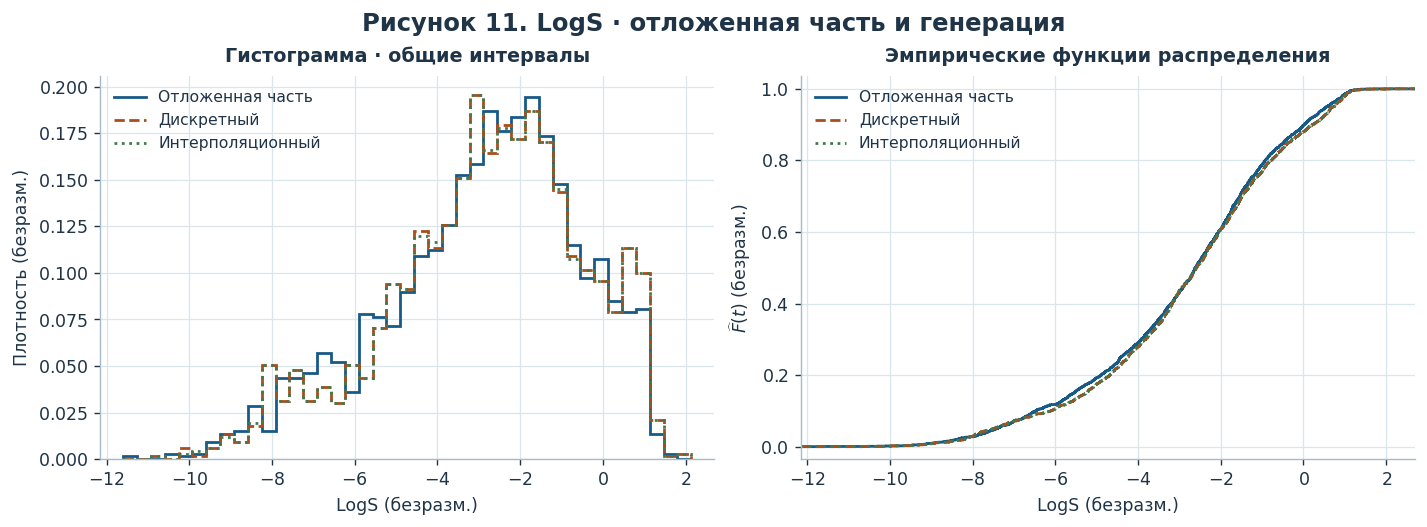

In [19]:
#@title Распределения LogS: общая сетка и эмпирические функции { display-mode: "form" }
s2_pool = np.r_[s2_test, s2_generated, s2_interpolated]
s2_edges = np.histogram_bin_edges(s2_pool, bins="fd")
s2_pad = .04 * np.ptp(s2_pool)
s2_lo, s2_hi = s2_pool.min() - s2_pad, s2_pool.max() + s2_pad
fig_s2, ax_s2 = plt.subplots(1, 2, figsize=(11.3, 4.1), layout="constrained")
fig_s2.suptitle("Рисунок 11. LogS · отложенная часть и генерация",
               fontsize=14, fontweight="bold")

for values_s2, label_s2, color_s2, style_s2 in (
    (s2_test, "Отложенная часть", BLUE, "-"),
    (s2_generated, "Дискретный", ORANGE, "--"),
    (s2_interpolated, "Интерполяционный", "#427951", ":"),
):
    density_s2, _ = np.histogram(values_s2, bins=s2_edges, density=True)
    np.testing.assert_allclose(np.dot(density_s2, np.diff(s2_edges)), 1)
    ax_s2[0].stairs(density_s2, s2_edges, color=color_s2, lw=1.6,
                    ls=style_s2, label=label_s2)
    unique_s2, count_s2 = np.unique(values_s2, return_counts=True)
    ax_s2[1].step(np.r_[s2_lo, unique_s2, s2_hi],
                  np.r_[0., np.cumsum(count_s2) / values_s2.size, 1.],
                  where="post", color=color_s2, lw=1.6, ls=style_s2, label=label_s2)

ax_s2[0].set(title="Гистограмма · общие интервалы", ylabel="Плотность (безразм.)",
             ylim=(0, None))
ax_s2[1].set(title="Эмпирические функции распределения",
             ylabel=r"$\widehat{F}(t)$ (безразм.)", ylim=(-.035, 1.035))
for axis_s2 in ax_s2:
    axis_s2.set(xlabel=LABEL["LogS"], xlim=(s2_lo, s2_hi))
    axis_s2.legend(loc="upper left")
show(fig_s2)


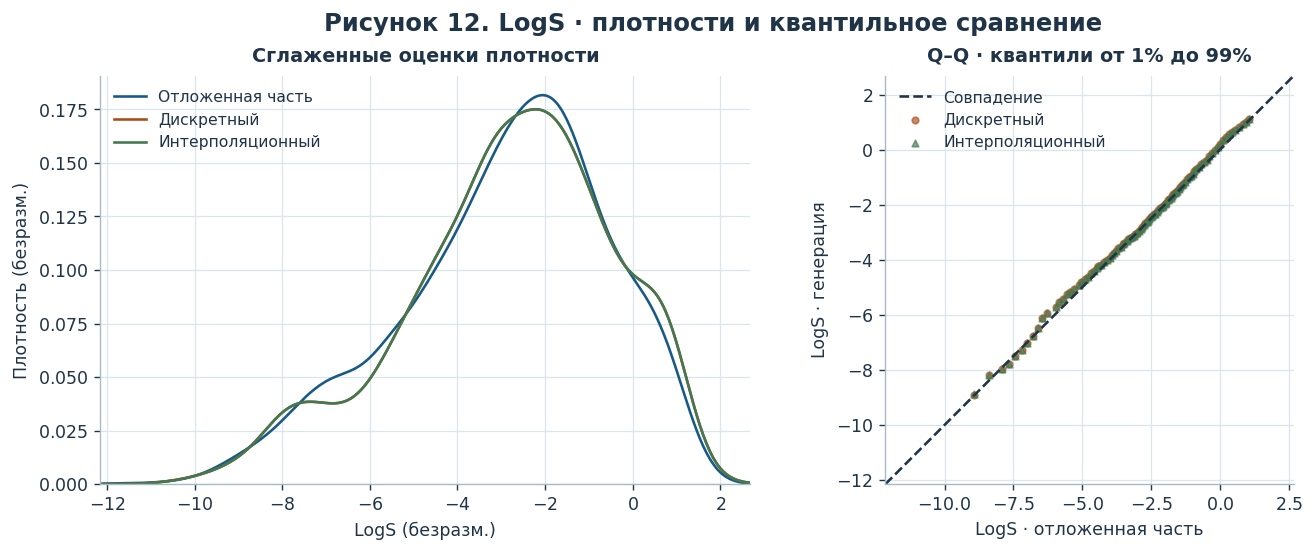

In [20]:
#@title Сравнение плотностей KDE и квантилей { display-mode: "form" }
fig, axes = plt.subplots(1, 2, figsize=(11.3, 4.3), layout="constrained")
fig.suptitle("Рисунок 12. LogS · плотности и квантильное сравнение",
             fontsize=14, fontweight="bold")
grid = np.linspace(s2_lo, s2_hi, 400)
quantile_levels = np.linspace(.01, .99, 99)
test_quantiles = np.quantile(s2_test, quantile_levels)
axes[0].plot(grid, stats.gaussian_kde(s2_test)(grid), color=BLUE, label="Отложенная часть")
axes[1].plot([s2_lo, s2_hi], [s2_lo, s2_hi], ls="--", color=INK, label="Совпадение")
for (name, (_, values)), color, marker in zip(s2_methods.items(), (ORANGE, "#427951"), ("o", "^")):
    axes[0].plot(grid, stats.gaussian_kde(values)(grid), color=color, label=name)
    axes[1].scatter(test_quantiles, np.quantile(values, quantile_levels), color=color,
                    alpha=.65, marker=marker, s=14, label=name)
axes[0].set(title="Сглаженные оценки плотности", xlabel=LABEL["LogS"],
            ylabel="Плотность (безразм.)", xlim=(s2_lo, s2_hi), ylim=(0, None))
axes[1].set(title="Q–Q · квантили от 1% до 99%", xlabel="LogS · отложенная часть",
            ylabel="LogS · генерация", xlim=(s2_lo, s2_hi), ylim=(s2_lo, s2_hi), aspect="equal")
for axis in axes:
    axis.legend(loc="upper left")
show(fig)


<a id="lab02-findings" name="lab02-findings"></a>

### 2.1.6 Вывод по генераторам

В зафиксированном запуске расстояние D до отложенных данных составило 0,0255 для обоих генераторов. По 300 повторам у каждого метода медиана D составила 0,0245, а интервал между 5-м и 95-м процентилями — примерно 0,0160–0,0361. По выбранной метрике заметного преимущества одного метода в этом эксперименте не видно.

При этом среднее обеих генераций оказалось выше отложенного примерно на 0,104, а квантиль 95% — на 0,175 у дискретного метода и на 0,173 у интерполяционного. Стандартное отклонение в обоих случаях почти совпало с отложенным.

Дискретный генератор воспроизводит закон обучающей части. Интерполяционный заполняет промежутки между соседними значениями и сохраняет её диапазон. Оба метода моделируют только LogS и не учитывают его связь с MolWt и MolLogP.

[К оглавлению](#lab01-toc)


In [21]:
#@title Численные итоги второго спринта { display-mode: "form" }
for name in s2_methods:
    delta = s2_differences[name]
    distance = s2_distances.loc[name]
    print(f"{name}: Δ среднего = {delta['Среднее']:+.4f}, "
          f"Δ станд. отклонения = {delta['Стандартное отклонение']:+.4f}, "
          f"Δ квантиля 95% = {delta['Квантиль 95%']:+.4f}.")
    print(f"D = {distance['D']:.4f}, 5–95-й процентили повторов: "
          f"{distance['5-й процентиль D']:.4f}–{distance['95-й процентиль D']:.4f}.")


Дискретный: Δ среднего = +0.1036, Δ станд. отклонения = -0.0002, Δ квантиля 95% = +0.1746.
D = 0.0255, 5–95-й процентили повторов: 0.0160–0.0361.
Интерполяционный: Δ среднего = +0.1038, Δ станд. отклонения = -0.0015, Δ квантиля 95% = +0.1729.
D = 0.0255, 5–95-й процентили повторов: 0.0160–0.0361.


<a id="lab02-resume" name="lab02-resume"></a>

## 2.2 Выводы по спринту 2

Последовательность работы вышла следующая: перенесли оба алгоритма из исходного ноутбука, проверили их автотестами и сравнили на общем разбиении AqSolDB. В конце добавили повторные генерации, чтобы вывод не зависел только от одной реализации.

Последняя ячейка этого раздела собирает в ZIP исходную и обработанную таблицы, метрики, графики и результаты генерации. Архив можно скачать из списка файлов Colab.


In [22]:
#@title Экспорт таблиц, графиков и генераций { display-mode: "form" }
import json
from zipfile import ZIP_DEFLATED, ZipFile

scaled = clean_rows.copy()
parameters = {}
for feature in FEATURES:
    x = data[feature]
    scaled[f"{feature}_z"] = (x - mu[feature]) / sd[feature]
    scaled[f"{feature}_minmax"] = (x - x.min()) / (x.max() - x.min())
    parameters[feature] = {
        "mean": float(mu[feature]), "std_ddof0": float(sd[feature]),
        "min": float(x.min()), "max": float(x.max()),
    }
scaled["MolWt_log10"] = np.log10(data["MolWt"])

population_statistics = data.describe().T.assign(
    variance=var, skewness=data.apply(stats.skew), excess=data.apply(stats.kurtosis),
)
population_statistics["std"] = sd
paths = {
    "aqsoldb_clean.csv": (clean_rows, False),
    "aqsoldb_scaled.csv": (scaled, False),
    "population_statistics.csv": (population_statistics, True),
    "iqr_flags.csv": (pd.DataFrame(eda_metrics).T[["lower", "upper", "flagged", "flagged_pct"]], True),
    "sample_with.csv": (sample_frames[True], False),
    "sample_without.csv": (sample_frames[False], False),
    "sample_comparison.csv": (samples, False),
    "convergence.csv": (mc, False),
    "mollogp_single_samples.csv": (logp_example_table, False),
    "correlation_pearson.csv": (corr_matrices["Пирсона"], True),
    "correlation_spearman.csv": (corr_matrices["Спирмена"], True),
    "independence.csv": (dependence, True),
    "permutation_tests.csv": (tests, True),
    "sprint2/generated.csv": (pd.DataFrame({"LogS": s2_generated, "LogS_interpolated": s2_interpolated}), False),
    "sprint2/metrics.csv": (s2_table, True),
    "sprint2/metrics_diff.csv": (s2_differences, True),
    "sprint2/distances.csv": (s2_distances, True),
}

conclusions_text = 'LogS имеет левый хвост, MolWt — выраженный правый хвост, а у MolLogP встречаются редкие крайние значения. Поэтому форму распределений оцениваем вместе со средним, разбросом, асимметрией и эксцессом.\n\nС ростом объёма выборки среднеквадратичная ошибка оценок в целом снижается. Абсолютная ошибка отдельной случайной выборки может колебаться. При отборе всех строк без возвращения среднее и дисперсия совпадают с показателями базы.\n\nВ AqSolDB все три пары признаков зависимы по проверке вероятностей. Самая сильная по модулю корреляция наблюдается между LogS и MolLogP: более липофильные соединения в этой базе обычно имеют меньшую растворимость.\n\nВ зафиксированном запуске расстояние D до отложенных данных составило 0,0255 для обоих генераторов. По 300 повторам у каждого метода медиана D составила 0,0245, а интервал между 5-м и 95-м процентилями — примерно 0,0160–0,0361. По выбранной метрике заметного преимущества одного метода в этом эксперименте не видно.\n\nПри этом среднее обеих генераций оказалось выше отложенного примерно на 0,104, а квантиль 95% — на 0,175 у дискретного метода и на 0,173 у интерполяционного. Стандартное отклонение в обоих случаях почти совпало с отложенным.\n\nДискретный генератор воспроизводит закон обучающей части. Интерполяционный заполняет промежутки между соседними значениями и сохраняет её диапазон. Оба метода моделируют только LogS и не учитывают его связь с MolWt и MolLogP.'
archive = Path("Lab01_AqSolDB_results.zip")
with ZipFile(archive, "w", compression=ZIP_DEFLATED) as bundle:
    bundle.writestr("aqsoldb_raw.csv", payload)
    bundle.writestr("source.json", json.dumps({"url": URL, "sha256": EXPECTED_SHA, "seed": SEED}, indent=2))
    bundle.writestr("scaling_parameters.json", json.dumps(parameters, indent=2))
    for name, (table, index) in paths.items():
        bundle.writestr(name, table.to_csv(index=index))
    bundle.writestr("conclusions.md", conclusions_text)
    for name, png in saved_figures.items():
        bundle.writestr(f"figures/{name}", png)
print(f"Архив результатов: {archive.name}")


Архив результатов: Lab01_AqSolDB_results.zip


<a id="lab02-refs" name="lab02-refs"></a>

### 2.2.1 Литература

- **Devroye, L. (1986).** Non-Uniform Random Variate Generation, гл. II, §2.1, «The inversion principle», и гл. III, §2, «The inversion method». [Глава в SpringerLink](https://link.springer.com/chapter/10.1007/978-1-4613-8643-8_2) · [Оглавление и сканы на сайте автора](https://luc.devroye.org/rnbookindex.html).
- **Sorkun, M. C., Khetan, A., Er, S. (2019).** AqSolDB, a curated reference set of aqueous solubility and 2D descriptors for a diverse set of compounds. [Scientific Data 6, 143](https://www.nature.com/articles/s41597-019-0151-1).
- **SciPy.** [Документация `scipy.stats.ks_2samp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ks_2samp.html): определение статистики и предпосылки стандартного теста.

[К оглавлению](#lab01-toc)


<a id="lab02-cat_mark_table" name="lab02-cat_mark_table"></a>

### 2.2.2 Критерии оценивания по спринту 2

| cat_id | notebook_link | coeff | comment |
|:---|:---|:---:|:---|
| 1 | [Генератор и математическое обоснование](#lab02-math) | – | Инверсия эмпирического закона и линейная интерполяция квантилей. |
| 2 | [Автотесты](#lab02-tests) | – | Воспроизводимость, размер, диапазон, границы, среднее, разбиение и интерполяция. |
| 3 | [Итоговые метрики и рисунок](#lab02-compare) | – | Сравнение на отложенной части; разброс статистики при повторных генерациях. |
| 4 | [Литература](#lab02-refs) | – | Монография по генераторам, статья о данных и документация статистики. |
| 5 | [Выводы по спринту 2](#lab02-resume) | – | Вывод по проделанной в спринте 2 работе. |

[К оглавлению](#lab01-toc)

<a id="lab01-criteria" name="lab01-criteria"></a>

### 2.2.3 Критерии оценивания для КТвД

В таблице обозначены критерии оценивания для КТвД. Пожалуйста, выставите баллы, как считаете нужным :)

| cat_id | notebook_link | coeff | comment |
|:---|:---|:---:|:---|
| 1 | Структура исследования | – | Общие методы, три вложенных блока признаков, общая проверка и выводы. |
| 2 | Индексы разделов | – | Сквозная нумерация разделов и подразделов. |
| 3 | Навигация | – | Оглавление, возврат к нему и переходы к общему анализу связей. |
| 4 | Скрытие кода | – | Технические ячейки свёрнуты, результаты и формулы видны. |
| 5 | Масштабы и единицы | – | Подписаны шкалы и единицы; нулевая ошибка не нанесена на логарифмическую ось. |
| 6 | Оформление графиков | – | Единый шрифт, палитра, нумерация и обозначения. |
| 7 | Формулы LaTeX | – | Единые обозначения вероятностей, моментов, выборочных оценок и критериев. |

[К оглавлению](#lab01-toc)